# [이론] Prophet — 가법 모형과 외생 변수

_이 노트북은 LMS에서 내보냈습니다. 영상·퀴즈는 학습 참고용으로 마크다운으로 변환되었습니다._

## 1. SARIMA 의 한계와 Prophet 의 예측 방식

<div style="background:#FFFFFF;color:#000000;padding:40px;border-radius:12px;border:1px solid #E6E6E6;border-left:4px solid #051C2C">
<div style="font-size:0.9em;color:#656565">AI 데이터 인텔리전스 전문가 과정 · 시계열 예측</div>
<h1 style="color:#000000;margin:10px 0">성분을 더해 만드는 예측 — Prophet</h1>
<div style="font-size:1.05em;color:#656565">날짜와 시각으로 추세·계절성·휴일 효과를 더하고 날씨를 외생 변수로 받는 예측 모형</div>
</div>

본문은 필수이고, 접힌 상자(「자세히」·「더 깊이」)는 선택입니다.

## 1. SARIMA 의 한계와 Prophet 의 예측 방식

서울 공유자전거 시간당 수요 예측에 셋째 날 SARIMA 를 그대로 둘까요, 성분을 더하는 Prophet 으로 바꿔 볼까요?

<details class="lms-extra"><summary>자세히 — 먼저 확인할 선행 개념 4가지</summary>

- **평균 제곱근 오차(root mean squared error, RMSE)** : 오차를 제곱해 평균한 뒤 제곱근을 씌운 예측 오차 지표이고, 값이 작을수록 예측이 실측에 가깝습니다 (첫날, 넷째 날 대표 지표)
- **평균 절대 스케일 오차(mean absolute scaled error, MASE)** : 채점하는 모형의 MAE(오차 절댓값의 평균)를 나이브 규칙의 MAE 로 나눈 배율입니다. 분모는 학습 구간에서 하루 전 같은 시각 값을 쓴 규칙(계절 나이브 24)의 MAE 입니다. 1 보다 작으면 그 나이브 규칙보다 덜 빗나갔다는 뜻입니다 (넷째 날)
- **분해(decomposition)와 잔차(residual)** : 계열을 추세·계절성분·잔차로 나누는 방법이고, 잔차는 두 성분으로 설명하고 남은 나머지입니다 (첫날)
- **예측구간(prediction interval)** : 다음에 실제로 관측될 값이 들어올 범위입니다 (셋째 날)

</details>

11월 17일 토요일 8시에는 530대가 대여됐습니다. 계수를 추정하지 않고 1주일 전 같은 시각 값을 그대로 쓰는 규칙(계절 나이브 168)을 **베이스라인(baseline)** 이라 합니다.

넷째 날처럼 10월 19일～11월 16일의 매주 금요일 23시를 **예측 원점(forecast origin)** 으로 둡니다. 원점은 학습을 끝내는 시각이고, 원점마다 그 뒤 168시간을 채점합니다.

| 방법 | 17일 8시 예측(실측 530대) | 예측 원점 5개 평균 RMSE(대/시간) |
|---|---|---|
| 셋째 날 SARIMA | 1,348대 | 385.06 |
| 베이스라인(계절 나이브 168) | 589대(11월 10일 8시 값) | 363.55 |

그래서 셋째 날 SARIMA 는 베이스라인을 넘지 못했습니다. 새 모형도 예측 원점 5개 평균 RMSE 가 363.55 보다 낮아야 운영에 씁니다.

운영팀의 질문은 3가지입니다.

1. 1년 추세는 어디에서 꺾였는가.
2. 성분을 더한 모형이 셋째 날 모형보다 나은가.
3. 날씨를 더하면 나아지는가.

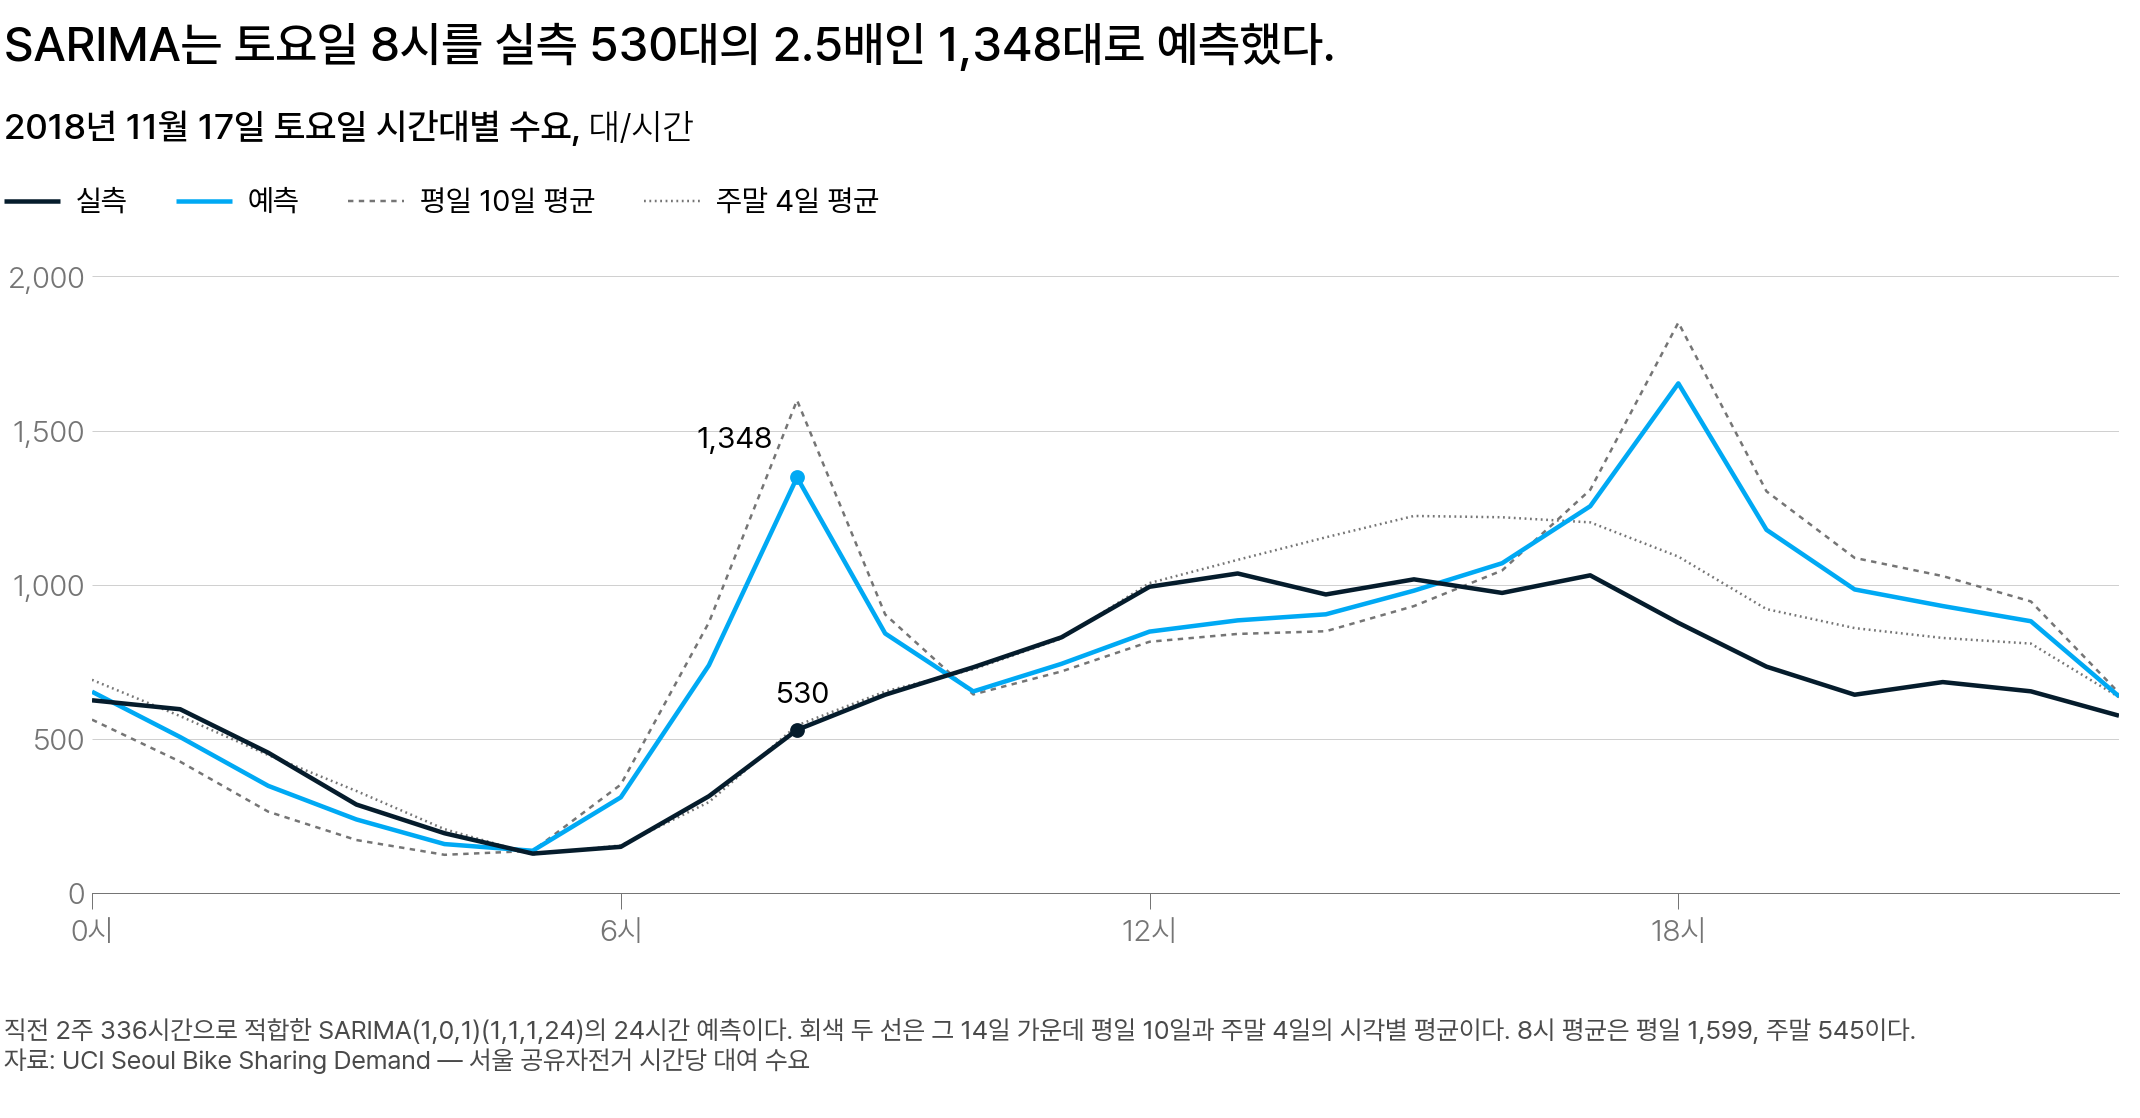

In [ ]:
# 도해 생성 코드는 LMS 에서만 실행됩니다

<p align="center"><em>▲ 2018년 11월 17일 토요일의 실측(남색)과 셋째 날 SARIMA 의 24시간 예측(하늘색), 회색 두 선은 학습 14일 가운데 평일 10일과 주말 4일의 시각별 평균이다. 예측은 평일 선 쪽에, 실측은 주말 선 옆에 있다</em></p>

| 8시 평균 | 값 | 가까운 것 |
|---|---|---|
| 평일 10일 | 1,599대 | |
| 주말 4일 | 545대 | 실측 530대 |
| 14일 전체 (10 × 1,599 + 4 × 545) ÷ 14 | 약 1,298대 | SARIMA 예측 1,348대 |

SARIMA 의 8시 예측은 평일과 주말을 합친 14일 평균을 따라갔습니다. SARIMA 는 **계절 주기 $m$(seasonal period)**, 곧 계절이 되풀이되는 간격을 하나만 받습니다. 셋째 날은 $m = 24$ 라 토요일 8시도 평일 8시와 같은 계수로 예측했습니다.

그래서 요일마다 다른 하루 모양을 따로 맞출 수 있는 모형이 필요합니다.

In [ ]:
# 셋째 날 SARIMA 로 11월 17일 토요일 8시를 다시 예측한다
import warnings
import pandas as pd
from statsmodels.tsa.statespace.sarimax import SARIMAX

try:
    raw = load_csv("datasets/SeoulBikeData.csv")            # LMS 에서는 LMS 가 올려 둔 자료를 이 함수로 읽는다
except NameError:                                           # Colab·내 컴퓨터에는 이 함수가 없어 UCI 원본 주소에서 받는다
    SRC = ("https://archive.ics.uci.edu/static/public/560/"
           "seoul+bike+sharing+demand.zip")
    raw = pd.read_csv(SRC, encoding="cp1252", compression="zip")
raw.columns = ["date", "count", "hour", "temp", "humidity", "wind", "visibility",
               "dewpoint", "solar", "rain", "snow", "season", "holiday", "functioning"]
raw.index = pd.to_datetime(raw["date"], format="%d/%m/%Y") + pd.to_timedelta(raw["hour"], unit="h")
raw = raw.sort_index()
s = raw["count"].astype(float).mask(raw["functioning"].eq("No"))   # 휴무 시각은 비워 두고
y = s.fillna(s.shift(168))                                          # 1주일 전 같은 시각 값으로 채우고
y = y.fillna(y.shift(-168))                                         # 앞 주가 없으면 1주일 뒤 값으로 채운다
y.index.freq = "h"

train = y["2018-11-03 00:00":"2018-11-16 23:00"]                    # 셋째 날과 같은 336시간
with warnings.catch_warnings():
    warnings.filterwarnings("ignore")                               # statsmodels 수렴 경고를 출력하지 않는다
    res = SARIMAX(train, order=(1, 0, 1), seasonal_order=(1, 1, 1, 24), trend="n").fit(disp=False)
    pred17 = res.get_forecast(24).predicted_mean.iloc[8]            # 17일 0시부터 9번째 = 8시
base168 = y["2018-11-10 08:00"]                                     # 베이스라인: 1주일 전 같은 시각 값

print(f"17일 토요일 8시: SARIMA {pred17:,.0f}대 · 베이스라인 {base168:,.0f}대 · 실측 {y['2018-11-17 08:00']:,.0f}대")
assert round(pred17) == 1348 and base168 == 589

## Prophet 은 무엇을 보고 예측하는가

**Prophet** 은 주기가 여럿이고 휴일 같은 달력 사건이 많은 계열을 위해 Meta 가 2017년에 만든 모형입니다. 셋째 날 SARIMA 는 1시간 전과 24시간 전의 값, 그리고 그때 빗나간 크기로 다음 값을 예측했습니다. Prophet 은 과거 값 대신 날짜와 시각을 보고, 그 시각에 정해진 기여분을 더해 예측합니다.

$$
\begin{aligned}
\text{SARIMA: } \hat{y}_t &= f(y_{t-1},\ y_{t-24},\ e_{t-1},\ e_{t-24}) \\
\text{Prophet: } \hat{y}(t) &= g({\color{#1f6feb}t}) + s({\color{#1f6feb}t}) + h({\color{#1f6feb}t})
\end{aligned}
$$

$g$·$s$·$h$ 는 추세·계절성·휴일 효과이고, 과거 수요는 기여분의 크기를 정하는 적합에만 씁니다. 식이 성분의 합이라 하루 주기와 1주일 주기를 함께 포함할 수 있습니다(SARIMA 는 $m$ 하나). 설처럼 날짜가 해마다 바뀌는 휴일도 목록으로 받습니다. 기온·강수처럼 계열 밖의 값을 항 하나로 더하는 **외생 변수(exogenous variable)** 도 받습니다.

11월 17일 토요일 8시를 예측할 때 두 모형이 보는 값입니다. **일간 계절성(daily seasonality)** 은 시각에 따라 더하는 기여분입니다. **주간 계절성(weekly seasonality)** 은 요일에 따라 더하는 기여분(요일 항)입니다.

| 모형 | 항 | 보는 값 | 묻는 질문 |
|---|---|---|---|
| SARIMA | 직전 값·오차 | 17일 7시 값(관측 전이라 예측값)과 오차(알 수 없어 0) | 한 시간 전 상황이 이어질까 |
| SARIMA | 계절 항 | 16일 8시 실측 1,692대와 그때 SARIMA 가 빗나간 크기 +167대 | 어제 같은 시각의 상황이 이어질까 |
| Prophet | 추세 $g(t)$ | 날짜 11월 17일 | 계절·휴일 효과를 빼면 이 무렵 수요는 얼마인가 |
| Prophet | 일간 계절성 | 시각 8시 | 8시라서 얼마를 더하나 |
| Prophet | 주간 계절성 | 요일 토요일 | 토요일이라서 얼마를 더하나 |
| Prophet | 휴일 효과 $h(t)$ | 휴일 목록 | 휴일이라서 얼마를 빼나 |

#### 그러면 Prophet 은 토요일 아침을 낮게 예측할까

기본 설정에서는 그렇지 않습니다. 셋째 날과 같은 336시간으로 적합한 Prophet 도 SARIMA 처럼 실측보다 높게 예측합니다.

| 추세 | 일간 계절성(8시) | 주간 계절성(토요일 8시) | 17일 8시 예측 | 실측 |
|---|---|---|---|---|
| 1,000.3대 | +159.1대 | +118.1대 | 1,277.5대 | 530대 |

그래서 성분을 더하는 모형도 기본 설정 그대로는 SARIMA 의 문제를 풀지 못합니다. 어떤 성분과 설정값을 쓰는지가 결과를 정합니다.

#### 두 모형에서 분석가가 정하는 값

Prophet 에서는 먼저 더할 성분을 고르고, 성분마다 하나씩 있는 설정값을 정합니다. 계절성을 포함할지는 학습 구간에 그 주기가 몇 번 되풀이되었는지로 판단합니다. 표의 학습 구간은 뒤에서 쓰는 9월 1일～11월 16일 1,848시간입니다.

| 선택지 | 특징 | 이런 경우에 쓴다 | 서울 공유자전거에서 | 설정값 |
|---|---|---|---|---|
| 추세 | 꺾일 수 있는 직선, 계절·휴일 효과를 뺀 그 무렵의 수요 | 모든 적합 | 추세는 모든 적합에 포함합니다. 계절성과 휴일 효과는 추세 값에 더하는 값이기 때문입니다 | **`changepoint_prior_scale`(추세 유연성)**: 추세가 얼마나 쉽게 꺾일지 |
| 일간 계절성 | 24시간 주기, 시각마다 더하는 기여분 | 시간 단위 자료일 때 | 학습 구간에 하루 주기가 77번 되풀이되어 일간 계절성을 포함합니다 | **푸리에 차수(`fourier_order`)**: 계절 곡선을 사인·코사인 곡선 몇 쌍으로 그릴지 |
| 주간 계절성 | 7일 주기, 요일마다 더하는 기여분 | 학습 구간에 여러 주가 있을 때 | 학습 구간에 한 주 주기가 11번 되풀이되어 주간 계절성을 포함합니다 | 푸리에 차수 |
| 연간 계절성(yearly seasonality) | 한 해 주기. 한 번뿐이면 같은 오르내림을 추세와 연간 계절성 어느 쪽이 맡을지 정해지지 않음 | 이력이 2년 이상일 때 | 1년치 자료에는 한 해 주기가 한 번뿐이라 연간 계절성을 제외합니다 | 푸리에 차수 |
| 휴일 효과 | 지정한 날에만 더하는 기여분 | 휴일 수요가 평소와 다를 때 | 설 당일 수요가 한 주 전 금요일의 41% 로 평소와 달라 휴일 효과를 포함합니다 | `holidays_prior_scale`: 관측이 적은 휴일 계수를 0 쪽으로 얼마나 줄일지 |

Prophet 은 설정 없이 빠르게 돌아가지만, 예측 오차가 늘 작지는 않습니다. 시계열 교과서 fpp3 는 『Forecasting: Principles and Practice』 3판의 약칭입니다. [fpp3 12.2 「Prophet model」](https://otexts.com/fpp3/prophet.html)의 시멘트 생산량 예에서도 Prophet 예측이 ARIMA 보다 더 빗나갔습니다. 그래서 fpp3 는 Prophet 이 계산은 빠르고 자동이지만 다른 방법보다 더 정확한 경우는 드물다고 정리합니다. 이 수업도 Prophet 을 쓸지는 베이스라인과 같은 조건에서 채점해 정합니다.

<div class="lms-summary">

**정리**

셋째 날 SARIMA 대신 Prophet 을 시도합니다. SARIMA 는 계절 주기 $m$ 을 하나(24)만 받아 토요일 8시를 1,348대로 예측했습니다(실측 530대). 예측 원점 5개 평균 RMSE 도 385.06 으로 베이스라인 363.55 보다 컸습니다.

- Prophet 에서는 더할 성분(추세·일간 계절성·주간 계절성·휴일 효과)을 고르고, 성분마다 설정값 `changepoint_prior_scale`·`fourier_order`·`holidays_prior_scale` 을 정합니다
- 기본 설정 그대로는 17일 8시를 1,277.5대로 예측해 설정을 바꿔 봐야 합니다. 바꾼 설정은 학습 오차가 아니라 학습에 쓰지 않은 기간의 오차로 견줍니다
- 새 구성은 예측 원점 5개 평균 RMSE 가 363.55 보다 낮을 때만 투입을 논의합니다

SARIMA 는 과거 값과 오차로, Prophet 은 날짜와 시각에 정해진 기여분으로 예측합니다.

</div>

## 2. 가법 모형 y = g + s + h + ε

Prophet 예측이 빗나갔을 때 그 값을 무엇의 합으로 읽고, 모형에 없는 영향은 어디서 찾을까요?

**가법 모형(additive model)** 은 성분들을 곱하지 않고 더해서 관측 하나를 만드는 모형입니다.

## 가법 모형의 식과 항 4개의 뜻

$$
y(t) = g(t) + s(t) + h(t) + \varepsilon_t
$$

- $y(t)$ : 시각 $t$ 의 관측값, 곧 대여 수요입니다
- $g(t)$ : **추세(trend)**, 계절성과 휴일 효과를 빼고 남는 긴 기간의 변동으로, Prophet 에서는 꺾일 수 있는 직선입니다
- $s(t)$ : **계절성(seasonality)**, 하루·한 주·한 해처럼 정해진 주기로 되풀이되는 변동입니다. 시간당 자료에서는 일간 계절성과 주간 계절성의 합입니다(일 수요면 연간 계절성과 주간 계절성)
- $h(t)$ : **휴일 효과(holiday effect)**, 휴일 계수에 **더미 변수(dummy variable)** 를 곱한 항입니다. 더미 변수는 그날이면 1, 아닌 날이면 0 인 열이라, 공휴일이 아닌 서울 1년의 347일은 $h(t) = 0$ 입니다
- $\varepsilon_t$ : **오차항(error term)**, 앞의 성분 3개가 설명하지 못하고 남은 값입니다

11월 17일 토요일 8시를 대입하면 $530 = 1{,}000.3 + (159.1 + 118.1) + 0 + \varepsilon_t$ 이라 $\varepsilon_t = -747.5$대입니다. 두 계절성은 수요를 오히려 올렸고, 실측과의 차이는 모두 오차항에 남았습니다.

그래서 이 빗나감은 성분의 크기를 고쳐서는 줄지 않습니다. 토요일 아침을 따로 낮출 성분이 있어야 줄어듭니다.

성분을 곱하는 구성도 있습니다. **곱셈 계절성(multiplicative seasonality)** 은 계절성의 기여분이 추세에 비례해 커진다고 보는 구성입니다. Prophet 에서는 `seasonality_mode='multiplicative'` 로 둡니다. 수요가 많은 철에는 하루 최대·최소 차이도 그만큼 커진다는 생각입니다.

휴무 시각을 빼고 보면 서울 공유자전거는 1월에서 6월로 시간당 평균이 약 6.2배, 하루 최대·최소 차이가 약 6.4배가 되었습니다. 이렇게 평균 대여량이 늘어난 만큼 하루 최대·최소 차이도 커지는 계열에는 곱셈 계절성이 가법보다 맞을 수 있습니다. Prophet [공식 문서](https://facebook.github.io/prophet/docs/multiplicative_seasonality.html)도 이런 계열에 곱셈 계절성을 씁니다. 기본 구성을 곱셈 계절성으로 바꿔 예측 원점 5개로 채점하면 평균 RMSE 가 381.47 에서 359.32 로 줄어 후보가 됩니다. 이 밖의 적합은 모두 가법입니다.

## 휴무 시각과 이상치를 다루는 방법

Prophet 은 `y` 가 빈 행을 빼고 적합합니다. 그래서 운영을 멈춘 시각(원본 `Functioning Day` 열이 No)이나 크게 튄 값(이상치)은 `None` 으로 비워 두면 됩니다.

휴무 시각의 0 은 수요가 아니라 대여를 받지 않은 시각이라, 그대로 두면 모형이 운영 중단을 수요 0 으로 배웁니다. 이상치를 그대로 두면 추세가 그 값에 맞춰 꺾여 예측구간이 지나치게 넓어집니다([Prophet 공식 문서 「Outliers」](https://facebook.github.io/prophet/docs/outliers.html)).

다만 계절 나이브 168 은 1주일 전 값이 비면 예측을 내지 못합니다. 그래서 Prophet 만 운영하면 비워 두고, 베이스라인과 견줄 때는 채웁니다. 여기서는 모든 방법을 같은 자료로 채점하려고 휴무 295시간을 1주일 전 같은 시각 값으로 채웠습니다. 휴일 효과를 포함한 Prophet 기본 구성을 9월 1일～11월 16일로 적합했습니다. 11월 17～23일 RMSE 는 비워 둘 때 305.54, 채울 때 310.34 로 4.80 차이였습니다.

## 서울 일 수요의 6월 9일을 식에 대입하기

가법 모형의 식을 서울 일 수요 365일에 적합하면 2018년 6월 9일 토요일은 이렇게 나뉩니다. 단위는 대/일이고, 괄호 안은 연간 계절성과 주간 계절성입니다.

$$
25{,}911 = 17{,}904 + (14{,}797 - 197) + 0 - 6{,}593
$$

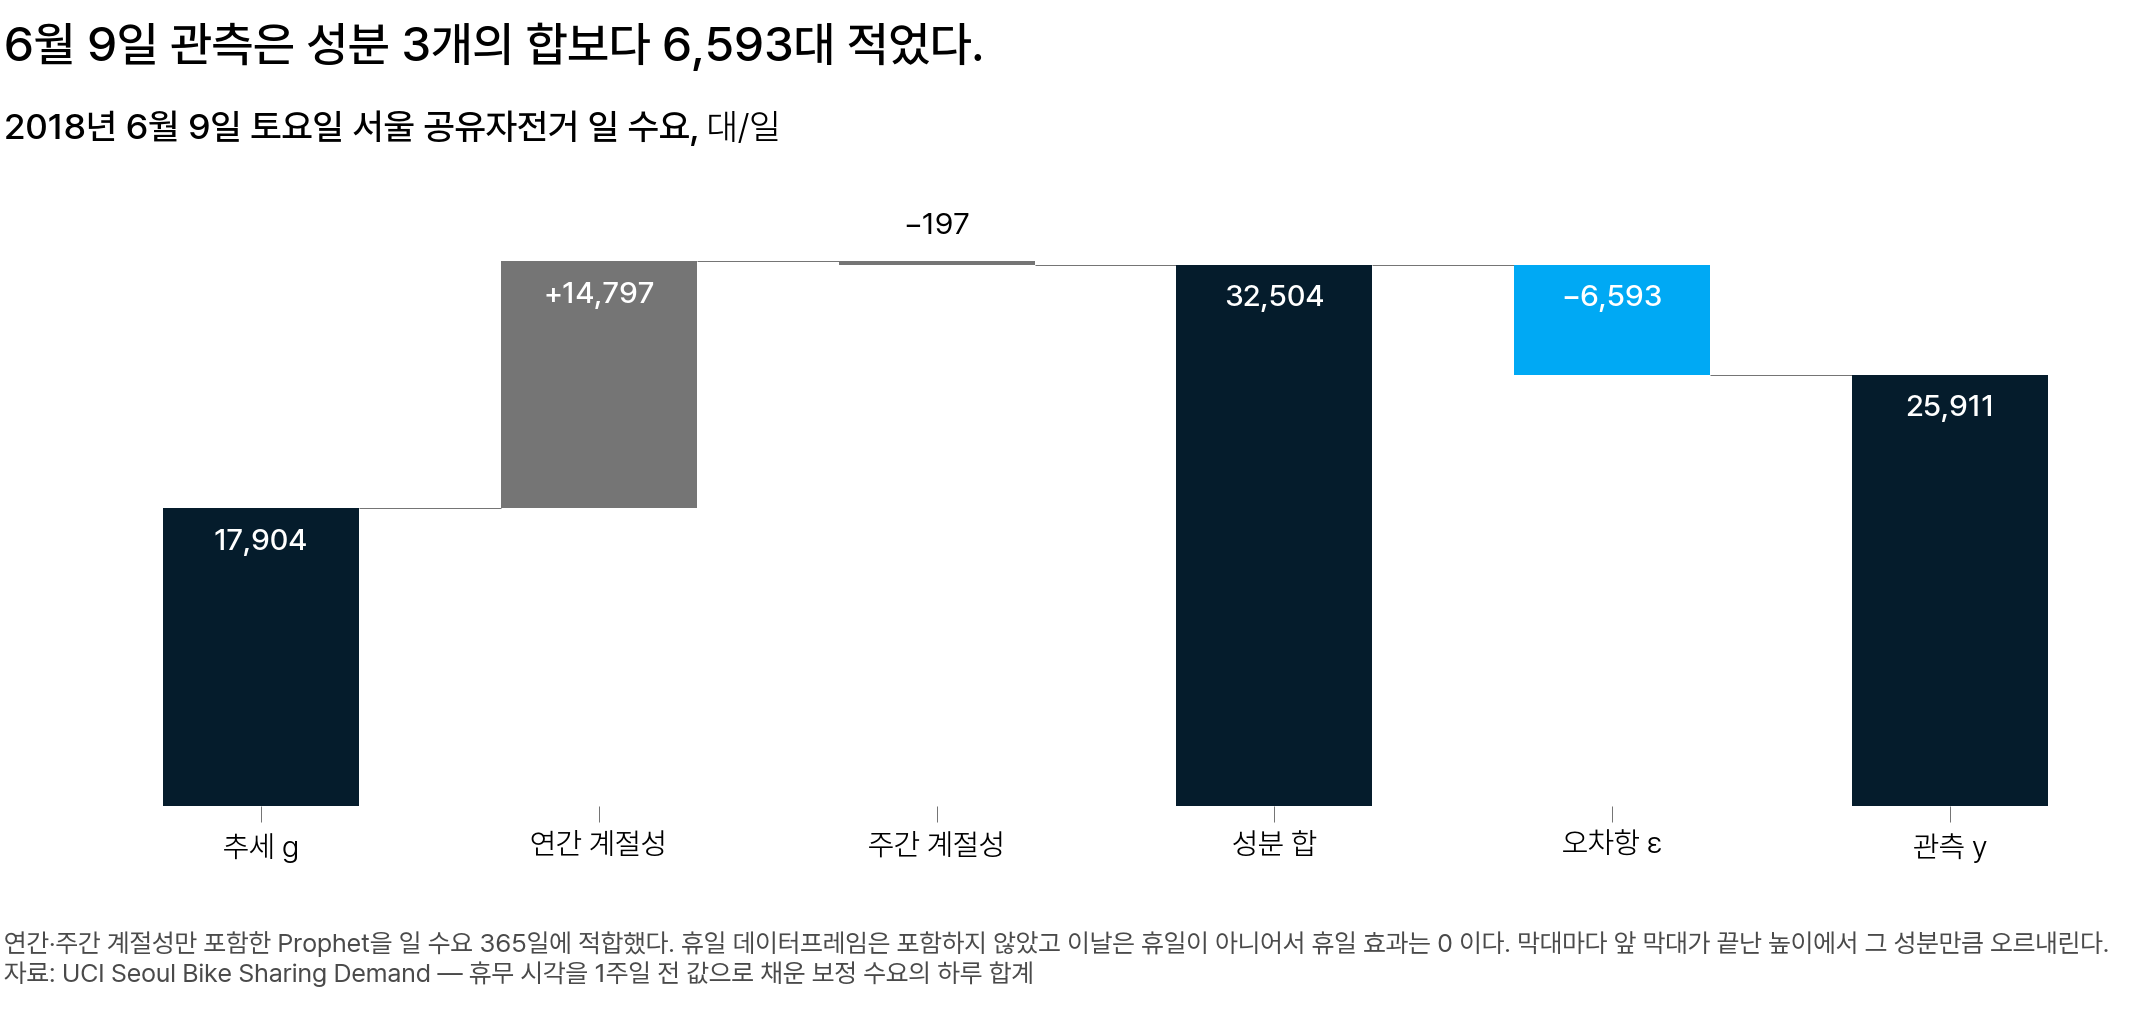

In [ ]:
# 도해 생성 코드는 LMS 에서만 실행됩니다

<p align="center"><em>▲ 2018년 6월 9일 토요일 서울 일 수요를 성분 차례로 더한 막대. 추세 17,904 에 연간 계절성 +14,797 과 주간 계절성 −197 을 더한 성분 합이 32,504 이고, 관측 25,911 과의 차이 −6,593(하늘색)이 오차항이다</em></p>

연간 계절성 +14,797 은 6월이 수요가 많은 철이라 더해진 기여분이고, 토요일의 주간 계절성 −197 은 하루 합계의 1% 도 안 됩니다. 그래서 일 수요의 하루 합계는 요일보다 철이 크게 바꿉니다. 1년치라 같은 오르내림을 추세와 연간 계절성 어느 쪽이 맡을지 자료가 정해 주지 못합니다. 그래서 17,904 와 14,797 은 식에 대입해 보는 예로만 쓰고 추세 값이나 연간 계절성 크기로 보고하지 않습니다.

오차항 −6,593 은 저녁에 몰려 있습니다. 그날 20～23시 수요는 2,013대로, 앞뒤 토요일 같은 시각(8,035·8,542대)보다 약 6,000대 적었습니다. 20시에는 비가 0.4mm 내렸습니다. 이 식에는 날씨 항이 없어 날씨로 줄어든 수요는 오차항에 남습니다. 그래서 날씨는 외생 변수로 더해 볼 후보가 됩니다.

In [ ]:
# 6월 9일 토요일은 어느 시각에 적었나: 앞뒤 토요일과 저녁 20~23시 비교
import pandas as pd

try:
    raw = load_csv("datasets/SeoulBikeData.csv")            # LMS 에서는 LMS 가 올려 둔 자료를 이 함수로 읽는다
except NameError:                                           # Colab·내 컴퓨터에는 이 함수가 없어 UCI 원본 주소에서 받는다
    SRC = ("https://archive.ics.uci.edu/static/public/560/"
           "seoul+bike+sharing+demand.zip")
    raw = pd.read_csv(SRC, encoding="cp1252", compression="zip")
raw.columns = ["date", "count", "hour", "temp", "humidity", "wind", "visibility",
               "dewpoint", "solar", "rain", "snow", "season", "holiday", "functioning"]
raw.index = pd.to_datetime(raw["date"], format="%d/%m/%Y") + pd.to_timedelta(raw["hour"], unit="h")
raw = raw.sort_index()
days = ["2018-06-02", "2018-06-09", "2018-06-16"]
ev = [raw.loc[d, "count"][20:].sum() for d in days]                # 20~23시 합계
print(f"6월 9일 토요일 20~23시 {ev[1]:,}대, 앞뒤 토요일 같은 시각 {ev[0]:,}·{ev[2]:,}대 · 20시 강수 {raw.loc['2018-06-09 20:00', 'rain']}mm")
for d in days:
    x = raw.loc[d]
    print(f"{d}  하루 {x['count'].sum():6,}대 · 20~23시 {x['count'][20:].sum():5,}대 · 강수 합 {x['rain'].sum():.1f}mm")
assert raw.loc["2018-06-09", "count"].sum() == 25911
assert [raw.loc[d, "count"][20:].sum() for d in ["2018-06-02", "2018-06-09", "2018-06-16"]] == [8035, 2013, 8542]
assert raw.loc["2018-06-09 20:00", "rain"] == 0.4

## 성분의 모양을 정해 두고 더하는 까닭

첫날 분해는 이미 관측한 값을 나눴습니다. Prophet 의 세 성분은 미래 날짜에서도 이렇게 값을 갖습니다.

- 추세: 마지막 기울기를 이은 직선
- 계절성: 주기대로 되풀이되는 값
- 휴일 효과: 달력의 다음 휴일에 다시 더하는 값

빠진 성분의 기여분은 오차항으로 갑니다. 첫날 분해에는 휴일 성분이 없어 광복절 8시의 잔차가 −1,151대/시간이었고, Prophet 은 이 휴일 효과를 $h(t)$ 로 떼어 냅니다.

<div class="lms-summary">

**정리**

Prophet 예측은 추세·계절성·휴일 효과를 더한 값으로 읽고, 모형에 없는 영향은 오차항에서 찾습니다. 11월 17일 8시는 오차항이 −747.5대였고, 6월 9일은 저녁 비로 −6,593대가 오차항에 남았습니다.

- 달력에 있는 사건(설·추석)은 휴일 효과 $h(t)$ 로, 달력에 없는 값(기온·강수)은 외생 변수(`add_regressor`)로 떼어 냅니다
- 성분은 가법(기본값)으로 두고, 평균 대여량이 많은 철에 하루 최대·최소 차이도 비례해 커지면 `seasonality_mode='multiplicative'` 를 학습 밖 오차로 견줍니다

가법 모형은 학습 구간에서 정한 성분을 미래 날짜에서 더해 예측합니다.

</div>

> **[문제] 성분 3개와 첫날의 분해**
>
> Prophet 의 성분 3개 $g(t)$·$s(t)$·$h(t)$ 를 첫날에 배운 분해의 성분(추세·계절성분·잔차)과 짝지어 보세요. 그리고 대응이 어긋나는 것이 하나 있는데, 그것이 무엇이고 왜 그런지도 한 문장으로 적어 보세요.

## 3. 추세 g(t): 변화점에서 기울기가 바뀌는 직선

Prophet 추세가 어디서 꺾였다고 보고하려면 어떤 변화점을 골라야 할까요?

Prophet 의 추세는 직선 여러 개를 이은 꺾은선입니다.

- **조각별 선형 함수(piecewise linear function)** 는 몇 시점에서만 기울기가 바뀌고 그 사이는 직선인 함수입니다.
- **변화점(changepoint)** 은 기울기가 바뀌는 시점입니다. 기호는 $s_j$ 이고, 계절성 $s(t)$ 와 구분하려고 늘 아래첨자와 함께 적습니다. 기울기만 바꿀 뿐 선을 끊지는 않습니다.

## 변화점 1개의 추세 계산

변화점이 하나인 추세를 말로 적으면 「추세값 = 오프셋 + 성장률 × 지난 날수 + 성장률 변화량 × 변화점 이후 지난 날수」입니다.

$$
g(t) = m + kt + \delta\,(t - s_1)\,\mathbf{1}[t \ge s_1]
$$

- $t$ : 지난 날수
- $m$ : **오프셋(offset)**, $t = 0$ 의 추세값입니다. 앞에서 SARIMA 의 계절 주기를 적던 $m$ 과는 다른 수입니다
- $k$ : **성장률(growth rate)**, 변화점 전 하루 증가분
- $s_1$ : **변화점**
- $\delta$ : **성장률 변화량(rate adjustment)**, 변화점 뒤 성장률에 더하는 값
- $\mathbf{1}[t \ge s_1]$ : 변화점을 지났으면 1, 아니면 0 인 표시함수(휴일 효과의 더미 변수와 같음)

작은 수를 대입해 봅니다. $m = 100$, $k = 5$ 로 출발해 12일째에 하루 증가분이 3 줄어드는 추세, 곧 $s_1 = 12$, $\delta = -3$ 입니다.

| 시각 $t$ | $\mathbf{1}[t \ge s_1]$ | $g(t)$ |
|---|---|---|
| 6일 | 0 | 100 + 5 × 6 = 130 |
| 12일 | 1 | 100 + 5 × 12 + (−3) × 0 = 160 |
| 23일 | 1 | 100 + 5 × 23 + (−3) × 11 = 182 |

12일에는 마지막 항이 (−3) × 0 = 0 이라 선이 끊기지 않고, 그 뒤로 하루 증가분은 5 + (−3) = 2 입니다.

<img src="https://upload.wikimedia.org/wikipedia/commons/7/7c/Piecewise_linear_function.svg" width="440" height="440"/>
<p align="center"><em>▲ 조각별 선형 함수. 파란 선이 3번 꺾이고 그 사이는 곧은 직선이다 (출처: Wikimedia Commons, Krishnavedala, CC0)</em></p>

꺾이는 3곳이 변화점이고, 변화점마다 같은 항이 하나씩 더해집니다. $j$ 번째 변화점을 $s_j$, 그 성장률 변화량을 $\delta_j$ 라 적고, $\delta_j = 0$ 이면 그 변화점은 추세를 바꾸지 않습니다.

<details class="lms-extra"><summary>더 깊이 — 추세·계단·기울기를 세로로 맞춘 변화점 3개의 그림</summary>

<img src="https://assets.mbrenndoerfer.com/_optimized/notebooks/prophet_files/prophet-linear-trend-changepoints-visualization-1920w.webp" width="640" height="787"/>
<p align="center"><em>▲ 변화점이 하는 일은 그 시점에서 기울기를 바꾸는 것이다. 위 그림의 추세, 가운데 그림의 계단, 아래 그림의 기울기가 세로로 맞아떨어져, 기울기는 한 구간 안에서 상수이고 변화점에서만 값이 달라진다 (출처: Marcel Brenndoerfer, "Prophet: Time Series Forecasting")</em></p>

맨 위 그림의 세로축 Trend Value 는 추세값이고, 맨 아래 그림의 Growth Rate 는 하루 증가분입니다. 증가분은 0.10 에서 0.07, 0.09, 0.08 로 바뀝니다. 그 차이 −0.03, +0.02, −0.01 이 변화점마다의 $\delta_j$ 입니다.

</details>

#### 왜 매끄러운 곡선이 아니라 꺾은선인가

곡선으로 맞추면 미래로 연장할 때 어느 방향으로 휘어질지가 정해지지 않습니다.

꺾은선의 마지막 직선이 그대로 이어지면 미래는 「마지막 기울기를 그대로 연장한다」 한 문장으로 정해집니다.

##### 직접 실행하기

아래 코드는 표의 계산을 그대로 옮긴 것이고, `np.where(t >= s, ...)` 가 식의 표시함수 $\mathbf{1}[t \ge s_1]$ 입니다.

In [ ]:
# 변화점에서 기울기가 바뀌는 조각별 선형 추세 - k=5, 변화점 12일, delta=-3
import numpy as np

k, m = 5.0, 100.0          # 성장률 k, 오프셋 m
s, delta = 12.0, -3.0      # 변화점이 놓인 날 s, 그 자리에서의 성장률 변화량 delta
t = np.arange(0, 24, dtype=float)
g = m + k * t + np.where(t >= s, delta * (t - s), 0.0)   # (t - s) 라서 변화점에서 값이 0 이 되고 선이 끊기지 않는다

print(f"하루 증가분: 변화점(12일) 전 {k:.1f} → 뒤 {k + delta:.1f}")
for day in (6, 12, 23):
    print(f"  {day:2d}일 지났을 때 추세값 {g[day]:6.1f}")
assert (g[6], g[12], g[23]) == (130.0, 160.0, 182.0)            # 표의 손계산과 같다

## 잠재적 변화점과 변화량이 큰 변화점

Prophet 은 꺾일 수 있는 날을 25곳 미리 둡니다. 후보마다 성장률 변화량 $\delta_j$ 를 하나씩 구하지만, 적합이 $\delta_j$ 를 0 쪽으로 당깁니다. 그래서 대부분은 0 근처에 머물고, 학습 오차를 크게 줄이는 후보만 0 에서 멀어집니다.

| 설정 | 기본값 | 쓰이는 때 | 하는 일 |
|---|---|---|---|
| `n_changepoints` | 25 | 적합 전 | 잠재적 변화점을 25곳 둔다 |
| `changepoint_range` | 0.8 | 적합 전 | 후보를 학습 구간 앞 80% 안에만 둬, 계열 끝의 우연한 기울기가 예측으로 이어지지 않게 한다 |
| `changepoint_prior_scale`(추세 유연성) | 0.05 | 적합하는 동안 | 후보마다 $\delta_j$ 를 0 쪽으로 당긴다. 작을수록 더 세게 당긴다 |
| 변화량이 큰 변화점의 기준(설정값 아님) | 0.01 | 적합 뒤 | $\delta_j$ 의 절댓값이 이보다 크면 변화량이 큰 변화점이 되고, 그림에 점선을 긋는다 |

- **잠재적 변화점(potential changepoint)** 은 꺾일 수 있는 후보로 둔 이 25곳입니다. 182일 학습이면 앞 약 145일 안에 대략 6일 간격입니다.
- **변화량이 큰 변화점(significant changepoint)** 은 적합 뒤 성장률 변화량 $|\delta_j|$ 가 0.01 을 넘은 곳입니다. 이보다 작은 $\delta_j$ 도 기울기를 조금 바꾸지만, 변화량이 큰 변화점에는 들지 않습니다.
- $\delta_j$ 는 수요와 날짜를 0 부터 1 사이로 바꿔 구한 값이라 단위가 없습니다. 서울 일 수요 182일에서는 최대 일 수요 31,681대를 181일로 나눈 175.0 을 곱하면 대/일이 됩니다. 그래서 기준 0.01 은 추세의 하루 증가분이 약 1.75대 바뀌는 크기입니다.

## 서울 일 수요 182일의 변화량이 큰 변화점

서울 일 수요의 2017년 12월～2018년 5월 182일에 이 식을 적합합니다. 반년치라 연간 계절성은 제외하고 주간 계절성만 포함했으니, 겨울에서 봄으로 오르는 흐름은 추세가 맡습니다.

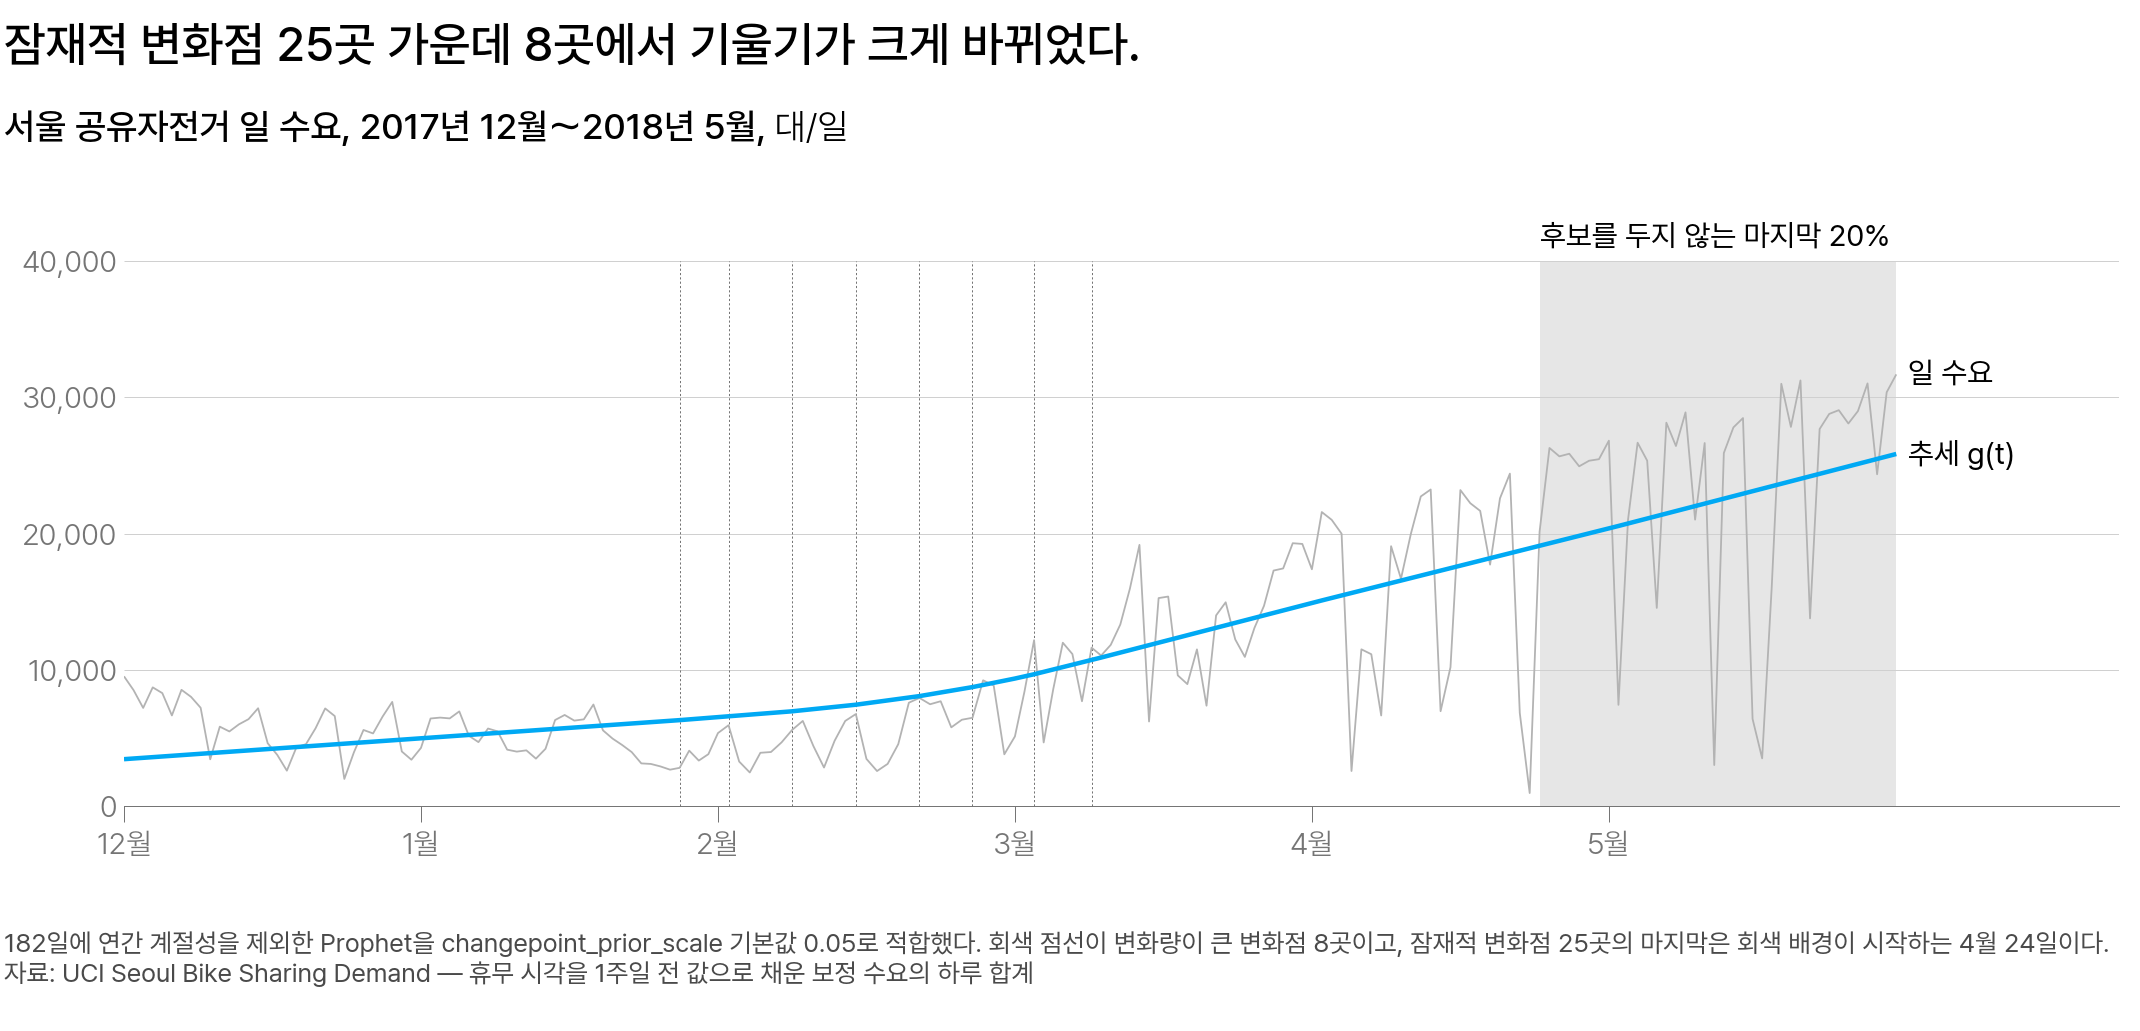

In [ ]:
# 도해 생성 코드는 LMS 에서만 실행됩니다

<p align="center"><em>▲ 서울 일 수요 182일(연회색)과 적합한 추세 g(t)(하늘색). 회색 세로 점선 8곳이 변화량이 큰 변화점이고 모두 1월 말～3월 초에 있으며, 마지막 잠재적 변화점인 4월 24일 뒤의 회색 배경에는 잠재적 변화점이 없다</em></p>

표에는 잠재적 변화점 25곳 가운데 네 날짜를 옮겼습니다.

| 후보 날짜 | 성장률 변화량 $\delta_j$ | 0.01 을 넘었나 |
|---|---|---|
| 1월 22일 | 0.0031 | 아니요 |
| 1월 28일 | 0.0287 | 예, 처음 넘은 곳 |
| 2월 20일 | 0.1521 | 예, 가장 크게 꺾인 곳 |
| 3월 9일 | 0.0475 | 예, 마지막으로 넘은 곳 |

12월～1월에 하루 약 49대씩 늘던 추세가 8곳을 지나며 하루 약 182대씩 느는 추세가 되었습니다. 그래서 이 추세를 그대로 미래로 이으면 봄의 가파른 증가가 여름에도 이어집니다. 그 기울기가 맞는지는 학습 뒤 기간의 오차로만 알 수 있습니다.

<details class="lms-extra"><summary>더 깊이 — 8년치 웹 트래픽의 변화량이 큰 변화점과 점선을 그리는 2행</summary>

Prophet 공식 예제인 위키백과 페이지뷰(8년치)에 기본 설정을 적합하면 변화량이 큰 변화점은 10곳입니다.

세로 점선은 아래 2행으로 Prophet 이 직접 그립니다. `fig.gca()` 는 방금 그린 그림의 그리기 영역(Axes 객체)을 가져옵니다.

**실행하지 않는 예**: 브라우저 실행기에는 prophet 패키지가 없고, `m`·`forecast` 는 앞선 적합의 결과라 여기서 만들 수 없습니다.

```
from prophet.plot import add_changepoints_to_plot

fig = m.plot(forecast)
add_changepoints_to_plot(fig.gca(), m, forecast)
```

</details>

<div class="lms-summary">

**정리**

추세가 꺾인 곳은 변화량이 큰 변화점($|\delta_j| > 0.01$)만 골라 보고합니다. 서울 일 수요 182일은 잠재적 변화점 25곳 가운데 8곳이었고, 하루 증가분이 약 49대에서 약 182대로 커졌습니다.

- 적합한 모형의 `m.params['delta'].mean(axis=0)` 에서 절댓값이 0.01 을 넘는 잠재적 변화점의 개수를 구합니다. 날짜는 `m.changepoints` 에 있습니다
- 그림에는 `add_changepoints_to_plot(fig.gca(), m, forecast)` 로 세로 점선을 긋습니다
- 보고할 때는 기울기가 바뀐 시기로 적고, 모형에 포함한 성분과 `changepoint_prior_scale` 을 함께 적습니다

운영팀 질문 1 의 답은 연간 계절성을 포함했는지에 따라 갈립니다. 연간 계절성을 제외한 이 182일 적합은 겨울에서 봄으로 오르는 계절 변동을 추세가 맡아 8곳입니다. 365일에 연간 계절성을 포함하면 0곳입니다.

변화량이 큰 변화점은 달력의 사건이 아니라 추세의 기울기가 바뀐 시기입니다.

</div>

> **[문제] 서울 일 수요 2017년 12월～2018년 5월 182일에서 변화량이 큰 변화점은 잠재적 변화점 25곳의 절반에 못 미친다.**
>
> 1. O (맞다)
> 2. X (틀리다)

## 4. 꺾임의 허용 정도를 정하는 changepoint_prior_scale

`changepoint_prior_scale` 은 몇으로 두어야 할까요?

꺾을수록 학습 오차는 줄지만, 우연한 변동까지 꺾임으로 받게 됩니다. 그래서 적합은 학습 오차에 꺾은 크기 $|\delta_j|$ 만큼 커지는 **페널티 항(penalty term)** 을 더합니다. 학습 오차가 페널티보다 더 줄어드는 후보에서만 $\delta_j$ 가 0 에서 멀어집니다.

**`changepoint_prior_scale`(추세 유연성)** 은 이 페널티를 얼마나 가볍게 둘지 정하는 값입니다. 기본값은 0.05 이고, 클수록 페널티가 가벼워 기울기가 크게 바뀔 수 있습니다.

## `changepoint_prior_scale` 을 바꾸면 꺾이는 곳은 어떻게 달라지나

같은 182일에 `changepoint_prior_scale` 만 0.01·0.05·0.5 로 바꿔 세 번 적합합니다.

0.01 에서는 잠재적 변화점 25곳의 $\delta_j$ 가 모두 0 에 가까워 추세가 직선 하나입니다. 변화량이 큰 변화점은 0.01·0.05·0.5 에서 0곳·8곳·6곳입니다. 0.5 는 1월 22일～2월 20일에 한꺼번에 크게 꺾어 봄의 가파른 기울기에 일찍 닿았고, 그 뒤로는 꺾지 않았습니다.

값을 키우면 한 곳에서 꺾이는 크기는 커질 수 있습니다. 그러나 변화량이 큰 변화점의 개수는 늘 수도 줄 수도 있어, 0.05 에서 0.5 로 가면 8곳에서 6곳이 됩니다.

`changepoint_prior_scale` 0.01·0.05·0.5 의 세 적합으로 학습 뒤 90일(2018년 6월 1일～8월 29일)을 예측해 봅니다.

> **[예측] changepoint_prior_scale 을 0.05 에서 0.5 로 키우면 어떻게 될까요?**
>
> 1. 학습 구간도 미래도 모두 더 정확해진다
> 2. 학습 구간은 더 잘 맞고, 미래 예측의 오차는 오히려 커진다
> 3. 학습 구간이 오히려 나빠지는 대신 미래가 안정된다
>
> 답을 정한 뒤 아래를 읽어 보세요(정답 채점은 없습니다).

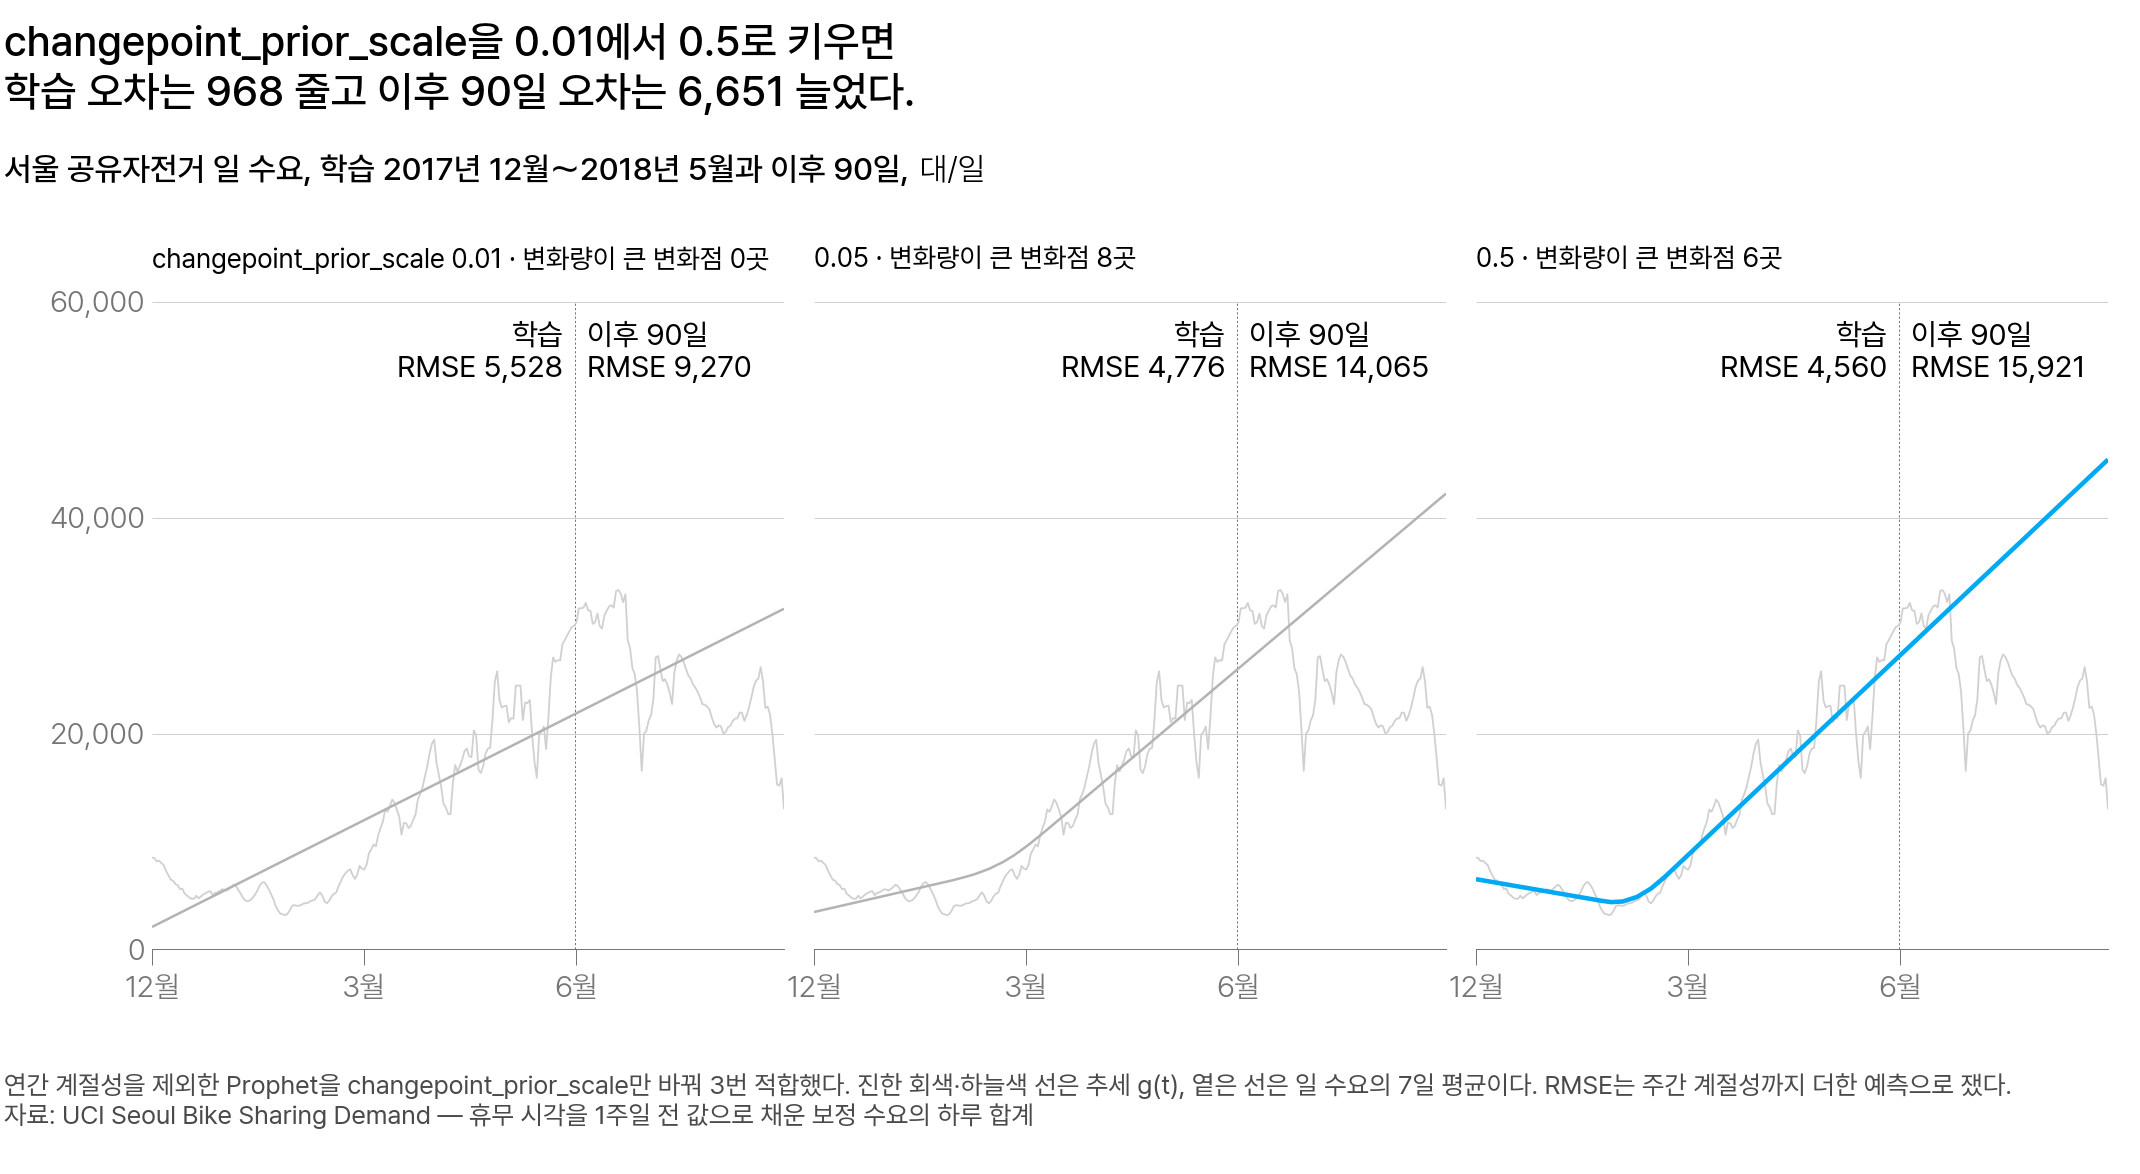

In [ ]:
# 도해 생성 코드는 LMS 에서만 실행됩니다

<p align="center"><em>▲ 서울 일 수요 182일로 학습하고 이후 90일을 예측한 추세 g(t). 그림은 왼쪽부터 changepoint_prior_scale 0.01·0.05·0.5 이고 점선 왼쪽이 학습, 오른쪽이 학습 뒤 90일이다</em></p>

예측 질문의 답은 두 번째입니다. 같은 비교를 12월～9월 학습, 10～11월 61일 예측으로 한 번 더 했습니다.

| `changepoint_prior_scale` | 12월～5월 학습 RMSE | 학습 뒤 90일(6～8월) RMSE | 12월～9월 학습 뒤 61일(10～11월) RMSE |
|---|---|---|---|
| 0.01 | 5,528 | 9,270 | 13,833 |
| 0.05 | 4,776 | 14,065 | 7,975 |
| 0.5 | 4,560 | 15,921 | 8,184 |

0.5 는 봄에 가파르게 오른 기울기를 여름 90일에도 그대로 이어 실제보다 높게 예측했습니다. 12월～9월로 학습하면 순서가 바뀌어, 0.05 가 가장 작고 직선 하나인 0.01 은 봄의 오름을 가을까지 이어 가 가장 크게 틀립니다.

그래서 한 기간의 오차만으로는 값을 고를 수 없습니다. 0.05 는 10～11월 기간에서 가장 작았고 6～8월 기간에서는 둘째였습니다. 그래서 기본값 0.05 를 두고, 학습 RMSE 가 가장 작은 0.5 는 쓰지 않습니다. 일 수요는 365일뿐이라 몇 달 길이의 학습 뒤 기간을 더 떼어 낼 수 없어, 예측 원점을 늘려 다시 고르지 않습니다. 원점 5개 비교의 Prophet 도 모두 0.05 로 적합했습니다.

### [직접 해보기] `changepoint_prior_scale` 을 키울 때 변화량이 큰 변화점이 생기는 위치

위젯의 계열은 앞 120일로 학습해 30일을 예측하는 합성 수요이고, 속 빈 원(`학습 뒤 실제 수요`)은 학습에 쓰지 않은 마지막 30일입니다. 아래 막대는 후보 20곳마다 성장률 변화량의 절댓값을 관측 최댓값으로 나눈 값(로그 스케일)입니다. 날짜를 0～1 로 바꾸지 않아 본문의 $\delta_j$ 와 크기는 다르지만 기준 0.01 규칙은 같습니다.

1. **해 보기.** `유연성 changepoint_prior_scale` 슬라이더를 0.001 부터 0.5 까지 움직여 봅니다.
2. **관찰.** 아래 막대가 `기준 0.01` 점선을 넘는 순간 위 그림에 `변화량이 큰 변화점` 세로 점선이 생기는지 봅니다. 오른쪽 `학습 RMSE`·`30일 예측 RMSE`·`30일 뒤 예측` 도 함께 바뀌는지 봅니다.
3. **확인 질문.** 움직이기 전에 예측해 보세요. 가장 작은 값에서 세로 점선은 몇 개나 남을까요. 그때 예측선은 꺾은선의 마지막 직선과 전체 기간 가운데 어느 쪽 기울기를 따를까요. 위젯의 합성 계열에서도 값을 키울수록 30일 예측이 나빠질까요.

In [ ]:
# 인터랙티브 위젯 — 셀을 실행하면 나타납니다 (인터넷 연결 필요)
# 아래가 잘려 보이면 height 값을 키우세요.
from IPython.display import IFrame
IFrame("https://aic-data.aiffel.io/api/widget-file/time-series/changepoint-lab.html", width=980, height=520)

<details class="lms-answer"><summary>답 확인 — changepoint_prior_scale 을 최솟값으로 둘 때의 변화량이 큰 변화점 수</summary>

0.001 에서 세로 점선은 0개입니다. 아래 그림에는 막대가 하나도 없고, 오른쪽 수치 영역에도 `후보 20곳의 변화량이 모두 0 입니다` 라는 문구가 나옵니다. 그래서 추세는 120일 전체를 지나는 직선 하나가 됩니다.

30일 뒤 예측은 마지막 30일의 내림을 무시한 채 전체 기간의 평균 기울기를 따라 163.5 까지 증가합니다. 30일 예측 RMSE 는 25.87 입니다.

기본값 0.05 에서는 점선이 4개(40.8·58.9·86.1·90.7일째)이고 30일 예측 RMSE 는 4.28, 0.5 에서는 7개에 3.52 입니다. 위젯의 합성 계열은 90일째부터 시작된 내림이 학습 뒤에도 이어지므로 꺾임을 따라간 쪽이 미래에도 맞습니다. 12월～5월로 학습한 서울 일 수요와는 방향이 반대입니다. 그래서 꺾임을 따라간 추세가 미래에도 맞는지는 계열마다 다르고, 학습에 쓰지 않은 기간의 오차로만 확인합니다.

</details>

<div class="lms-summary">

**정리**

`changepoint_prior_scale` 은 기본값 0.05 로 둡니다. 0.05 는 학습 뒤 10～11월 61일에 가장 작고(7,975) 6～8월 90일에 둘째였습니다(14,065). 학습 RMSE 가 가장 작은 0.5 는 여름 90일에 가장 크게 틀렸습니다(15,921).

- 후보는 10배 간격(0.01·0.05·0.5)으로 두고, 학습 RMSE 가 아니라 학습에 쓰지 않은 기간의 RMSE 로 고릅니다
- 한 기간의 순위는 학습 끝의 철에 따라 바뀌므로 기간을 둘 이상 두고 함께 적습니다
- 변화량이 큰 변화점 수를 보고할 때 이 값을 함께 적습니다(0.01·0.05·0.5 에서 0곳·8곳·6곳)

`changepoint_prior_scale` 은 과거의 꺾임을 얼마나 따라갈지를 정하고, 알맞은 값은 학습에 쓰지 않은 기간의 오차로 고릅니다.

</div>

## 5. 계절성 s(t): 사인·코사인 항의 합

평일과 주말의 하루 모양이 다를 때 일간 계절성을 어떻게 두어야 할까요?

서울 1년치를 시각별로 평균한 값입니다.

- 새벽 4시: 138대/시간(가장 적음)
- 8시: 1,064대/시간
- 18시: 1,580대/시간

8시와 18시는 앞뒤 시각보다 많아, 수요가 많은 시각이 하루에 두 곳입니다.

**사인 곡선** 은 같은 간격마다 같은 높이만큼 올라갔다 내려오기를 되풀이하는 매끈한 곡선입니다. **코사인 곡선** 은 같은 모양을 시작점만 옮긴 것입니다. 24시간마다 한 번 오르내리는 사인 곡선은 하루 주기를 가장 단순하게 그린 모양입니다.

**푸리에 급수(Fourier series)** 는 오르내리는 횟수가 다른 사인·코사인 곡선들을 크기를 달리해 더한 주기 곡선입니다. 대부분의 주기 곡선은 이 합으로 만들 수 있습니다.

## 항 N 쌍을 더한 식

말로 적으면 계절 곡선은 「1번째 항의 코사인 × 크기 + 1번째 항의 사인 × 크기 + … + $N$ 번째 항의 사인 × 크기」입니다.

$$
s(t) = \sum_{n=1}^{N} \left[ a_n \cos(2\pi n t / P) + b_n \sin(2\pi n t / P) \right]
$$

- $t$ : **시점**(지난 날수나 시간 수)
- $P$ : **주기(period)**, 한 주 7일·한 해 365.25일·하루 24시간
- $n$ : **몇 번째 항인가**, $n$ 번째 항은 한 주기 안에서 $n$ 번 오르내립니다
- $2\pi$ : $t$ 가 $P$ 만큼 지나면 곡선이 한 번 다 오르내리게 맞춘 수입니다. $P = 7$ 이면 $t = 7$ 에서 $\sin(2\pi) = 0$ 으로 $t = 0$ 과 같습니다
- $a_n, b_n$ : 그 항의 **크기**이고 자료가 정합니다. 두 계수의 비는 가장 높은 시점을 정합니다
- $N$ : 몇 번째 항까지 쓸지 정하는 **푸리에 차수 N(`fourier_order`)**

## 왜 항 한 쌍으로는 부족한가

항 한 쌍은 계수를 어떻게 정해도 한 주기에 한 번 오르내리고, 가장 높은 시점만 옮겨 갑니다. 「주말 2일만 높고 평일 5일은 낮다」처럼 2 대 5 로 갈리는 모양은 계수를 어떻게 바꾸어도 나오지 않습니다. 각진 모양을 만들려면 한 주기 안에서 더 여러 번 오르내리는 항이 함께 있어야 합니다.

<img src="https://upload.wikimedia.org/wikipedia/commons/2/2c/Fourier_Series.svg" width="320" height="569"/>
<p align="center"><em>▲ 사인·코사인 항을 위에서 아래로 하나씩 더할수록 빨간 근사 곡선이 파란 계단 모양 목표에 가까워진다. 계단 윗면에서 빨간 곡선이 오르내리는 횟수는 항마다 늘고, 계단이 바뀌는 곳 옆에서는 계단보다 높은 값이 남는다. 그림은 위에서부터 항 1·2·3·4개다 (출처: Wikimedia Commons, Jim Belk, Public domain)</em></p>

##### 직접 실행하기

주간 모양 하나를 목표로 두고 $N$ 을 1, 2, 3, 4 로 늘리며 얼마나 가까워지는지 측정합니다. 목표는 평일 5일이 −1 이고 주말 2일이 +2.5 인 각진 모양입니다. 위 식에는 상수항이 없어, 모형에서 추세 $g(t)$ 가 맡는 평균 높이를 코드에서는 모든 행이 1 인 열로 둡니다.

In [ ]:
# 푸리에 항을 몇 쌍까지 더해야 주간 모양이 맞나 - P=7, N=1/2/3/4
import numpy as np

target = np.array([-1.0, -1.0, -1.0, -1.0, -1.0, 2.5, 2.5])   # 월~금 낮고 주말 높은 모양
t = np.arange(7.0)

errs = {}
for N in (1, 2, 3, 4):
    cols = [np.ones(7)]                                        # 평균 높이 1 을 맡는 열
    for n in range(1, N + 1):
        cols += [np.cos(2 * np.pi * n * t / 7), np.sin(2 * np.pi * n * t / 7)]
    X = np.column_stack(cols)
    beta, *_ = np.linalg.lstsq(X, target, rcond=None)
    errs[N] = np.abs(X @ beta - target).max()                  # 7개 시점에서 가장 큰 오차

first = min(N for N, e in errs.items() if e < 1e-9)
print(f"결론: 차수 {first} 에서 요일 7개 값을 오차 없이 지난다")
for N, err in errs.items():
    print(f"차수 {N} (계수 {1 + 2 * N}개 = 평균 높이 1 + 사인·코사인 {2 * N}개): 가장 큰 오차 {err:.3f}")
assert first == 3 and round(errs[1], 3) == 1.401 and round(errs[2], 3) == 0.445 and errs[4] < 1e-9

한 주 7일(일별 자료)에 항을 더할 때입니다.

| 차수 $N$ | 계수 수(평균 높이 1 + $2N$) | 가장 큰 오차 |
|---|---|---|
| 1 | 3 | 1.401 |
| 2 | 5 | 0.445 |
| 3 | 7 = 요일 수 | 0.000 |
| 4 | 9 | 0.000(새 모양 없음) |

계수가 요일 수 7 과 같아지는 $N = 3$ 에서 7개 값을 모두 지납니다. 그래서 차수의 상한은 한 주기 안의 시점 수를 2로 나눈 값의 정수 부분이고, 하루 24시각이면 12 입니다. 일별 자료에서 Prophet 주간 계절성의 기본값 3 도 이 상한과 같습니다.

### [직접 해보기] 사인·코사인 항을 더할수록 달라지는 하루 곡선

위젯의 남색 점 24개(`서울 시각별 평균`)는 1년치 시각별 평균을 전체 평균 737.85대로 나눈 값입니다. 8시 1,064대는 1.44, 18시 1,580대는 2.14 가 됩니다. 높이 1 은 모형에서 추세 $g(t)$ 의 기여분에 해당합니다.

1. **해 보기.** 그림 아래 `푸리에 차수 N (fourier_order)` 슬라이더를 1 부터 12 까지 움직여 봅니다. `항별 값을 볼 시각` 슬라이더로 시각을 고르면, 그 시각의 합성값이 1 에 항별 값을 더한 식으로 나옵니다.
2. **관찰.** 하늘색 `합성 곡선` 이 남색 점에 얼마나 가까워지는지, 아래 그림에서 방금 더한 항이 어느 시각에서 양수이고 어느 시각에서 음수인지를 봅니다.
3. **확인 질문.** 움직이기 전에 예측해 보세요. 수요가 많은 시각이 두 곳인 하루 곡선을 만들려면 최소 몇 번째 항까지 필요할까요. 그리고 12 에서 24개 점을 모두 지나게 되면, 점과 점 사이의 곡선도 목표를 따를까요.

In [ ]:
# 인터랙티브 위젯 — 셀을 실행하면 나타납니다 (인터넷 연결 필요)
# 아래가 잘려 보이면 height 값을 키우세요.
from IPython.display import IFrame
IFrame("https://aic-data.aiffel.io/api/widget-file/time-series/fourier-lab.html", width=980, height=520)

<details class="lms-answer"><summary>답 확인 — 많은 시각이 두 곳인 곡선에 필요한 항과 점 사이의 굴곡</summary>

수요가 많은 시각이 두 곳인 모양은 $n = 2$ 항이 있어야 만들어집니다. $N = 1$ 에서는 가장 높은 시각이 17시 하나뿐이고, $N = 2$ 가 되는 순간 10시와 19시 두 곳이 앞뒤 시각보다 높아집니다. 다만 높이가 모자랍니다. $N = 3$ 에서도 8시 합성값은 $1 + (-0.422) + 0.309 + 0.105 = 0.992$ 로 목표 1.44 에 못 미칩니다.

$N = 12$ 에서는 24개 점을 모두 지나 오차가 0 입니다. 시각이 24개라 항은 12쌍이 상한이고, 한 주 7일에서 3쌍이 상한이었던 것과 같은 규칙입니다. 그런데 점과 점 사이는 목표가 정하지 않은 구간이라, 9시와 10시 사이에서 곡선이 0.72 까지 내려갑니다. 9시 0.91 과 10시 0.75 보다 낮은 값입니다. 점에서 오차가 0 인 것과 곡선이 자료의 모양을 옳게 그린 것은 다른 일입니다.

</details>

## 차수를 늘리면 새 기간에서도 나아지는가

푸리에 차수(`fourier_order`)는 계절 곡선을 사인·코사인 몇 쌍으로 그릴지 정하는 값이고, 기본값은 일간 4·주간 3·연간 10 입니다. 쌍이 많을수록 곡선이 한 주기 안에서 더 여러 번 굽어, 8시처럼 한 시각에 몰린 수요도 그릴 수 있습니다. 서울 공유자전거에서는 일간 계절성의 차수를 4 에서 10 으로 키우자 한 주 검증 RMSE 가 310.34 에서 281.4 로 줄었습니다. 하루 24시각이라 사인·코사인은 12쌍이 상한인데, 이를 넘긴 20·40 도 280.0 으로 10 과 1.4 차이뿐입니다. 예측 원점 5개 평균으로도 차수 10 이 358.41 로 기본값 4 의 381.47 보다 낮아, 차수 10 을 후보로 둡니다.

하루 주기는 학습 1,848시간에 77번 되풀이되어, 차수를 키워도 그 기간에만 있던 변동이 곡선에 들어갈 여지가 적습니다. 1년치 자료의 한 해 주기처럼 한 번뿐인 주기는 차수를 키우면 그해에만 있던 변동까지 들어와 새 기간에서 더 틀립니다. 이것을 **과적합(overfitting)** 이라 합니다. 그래서 차수는 기본값에서 시작해 학습에 쓰지 않은 기간의 오차로 고릅니다.

<details class="lms-extra"><summary>더 깊이 — 한 해에 12개 시점뿐인 월별 자료의 푸리에 차수</summary>

<img src="https://otexts.com/fpp3/fpp_files/figure-html/eatout-1.png" width="640" height="512"/>
<p align="center"><em>▲ 푸리에 차수 K 를 1 에서 6 까지 늘린 모형 6개. K 가 커질수록 예측선이 한 해 안에서 더 잘게 오르내린다. 검은 선이 월별 관측이고 색 선과 옅은 면이 2019년 이후 예측과 95% 예측구간이다. 자료는 호주 외식 지출 월별, 세로축 billions 는 달러 십억 단위 지출, 가로축 Month 는 월이다 (출처: Hyndman & Athanasopoulos, FPP3 Figure 10.11)</em></p>

그림 위쪽 회색 라벨의 $K$ 는 앞 식의 $N$ 과 같은 양입니다. 월별 자료라 한 해에 시점이 12개뿐이고, 쓸 수 있는 항의 상한은 12 를 2로 나눈 6 입니다. 이 그림의 모형은 ARIMA 오차에 푸리에 항을 더한 회귀이고, 원 교재는 AICc 가 가장 낮은 K = 6(−917.50)을 고릅니다.

그림마다 적힌 AICc 는 학습 표본 안에서 측정한 적합도에 계수 개수만큼 페널티를 더한 값입니다. 둘째 날에 쓴 AIC 와 같은 종류의 점수이고, 여기에서는 K 가 커질수록 줄어듭니다. 다만 그 곡선이 다음 해에도 되풀이되는지는 이 점수가 검사하지 못합니다. 상한이 늘 과적합인 것도 아닙니다. 앞의 코드는 평일 5일이 −1, 주말 2일이 +2.5 인 주간 모양을 $N = 3$ 에서 최대 오차 0.000 으로 맞췄습니다. 이처럼 목표가 잡음 없는 격자값이면 상한이 정답입니다.

</details>

## 왜 주간 계절성은 토요일 아침을 낮추지 못하는가

주간 계절성은 요일마다 더하는 값이라 토요일 아침도 낮출 것 같습니다. 그런데 336시간 적합의 17일 토요일 8시 예측은 1,277.5대로, 실측 530대보다 747.5대 많습니다.

휴일이 아닌 날의 예측은 계절성 $s(t)$ 를 일간과 주간으로 나눠 이렇게 적습니다.

$$
\hat{y}(t) = \underbrace{g(t)}_{\text{추세}} + \underbrace{s_{\text{일간}}(t)}_{\text{일간 계절성}} + \underbrace{s_{\text{주간}}(t)}_{\text{주간 계절성}}
$$

- $g(t)$ : 계절·휴일 효과를 뺀 그 무렵의 수요
- $s_{\text{일간}}(t)$ : 시각마다 더하는 값. 모든 요일에 같은 24시간 곡선 하나입니다
- $s_{\text{주간}}(t)$ : 요일마다 더하는 값. 한 주 168시간에 걸친 완만한 곡선 하나라, 하루 안에서도 조금씩 오르거나 내립니다

17일 8시에 대입하면 이렇습니다.

$$
\underset{\text{예측}}{1{,}277.5} = \underset{\text{추세}}{1{,}000.3} + \underset{\text{일간}}{159.1} + \underset{\text{주간}}{118.1}
$$

- 추세 1,000.3대: 이 항만으로 실측 530대보다 470.3대 많습니다. 하루 전체가 높은 까닭입니다
- 일간 계절성 +159.1대: 16일 금요일 8시에 더한 값과 같습니다. 금요일 출근 수요가 토요일에도 붙었습니다
- 주간 계절성 +118.1대: 토요일인데 오히려 더합니다

그래서 17일의 빗나감에는 원인이 둘 있습니다. 하루 전체가 높은 것은 추세 때문이고, 8시가 특히 높은 것은 요일마다 같은 하루 곡선 때문입니다.

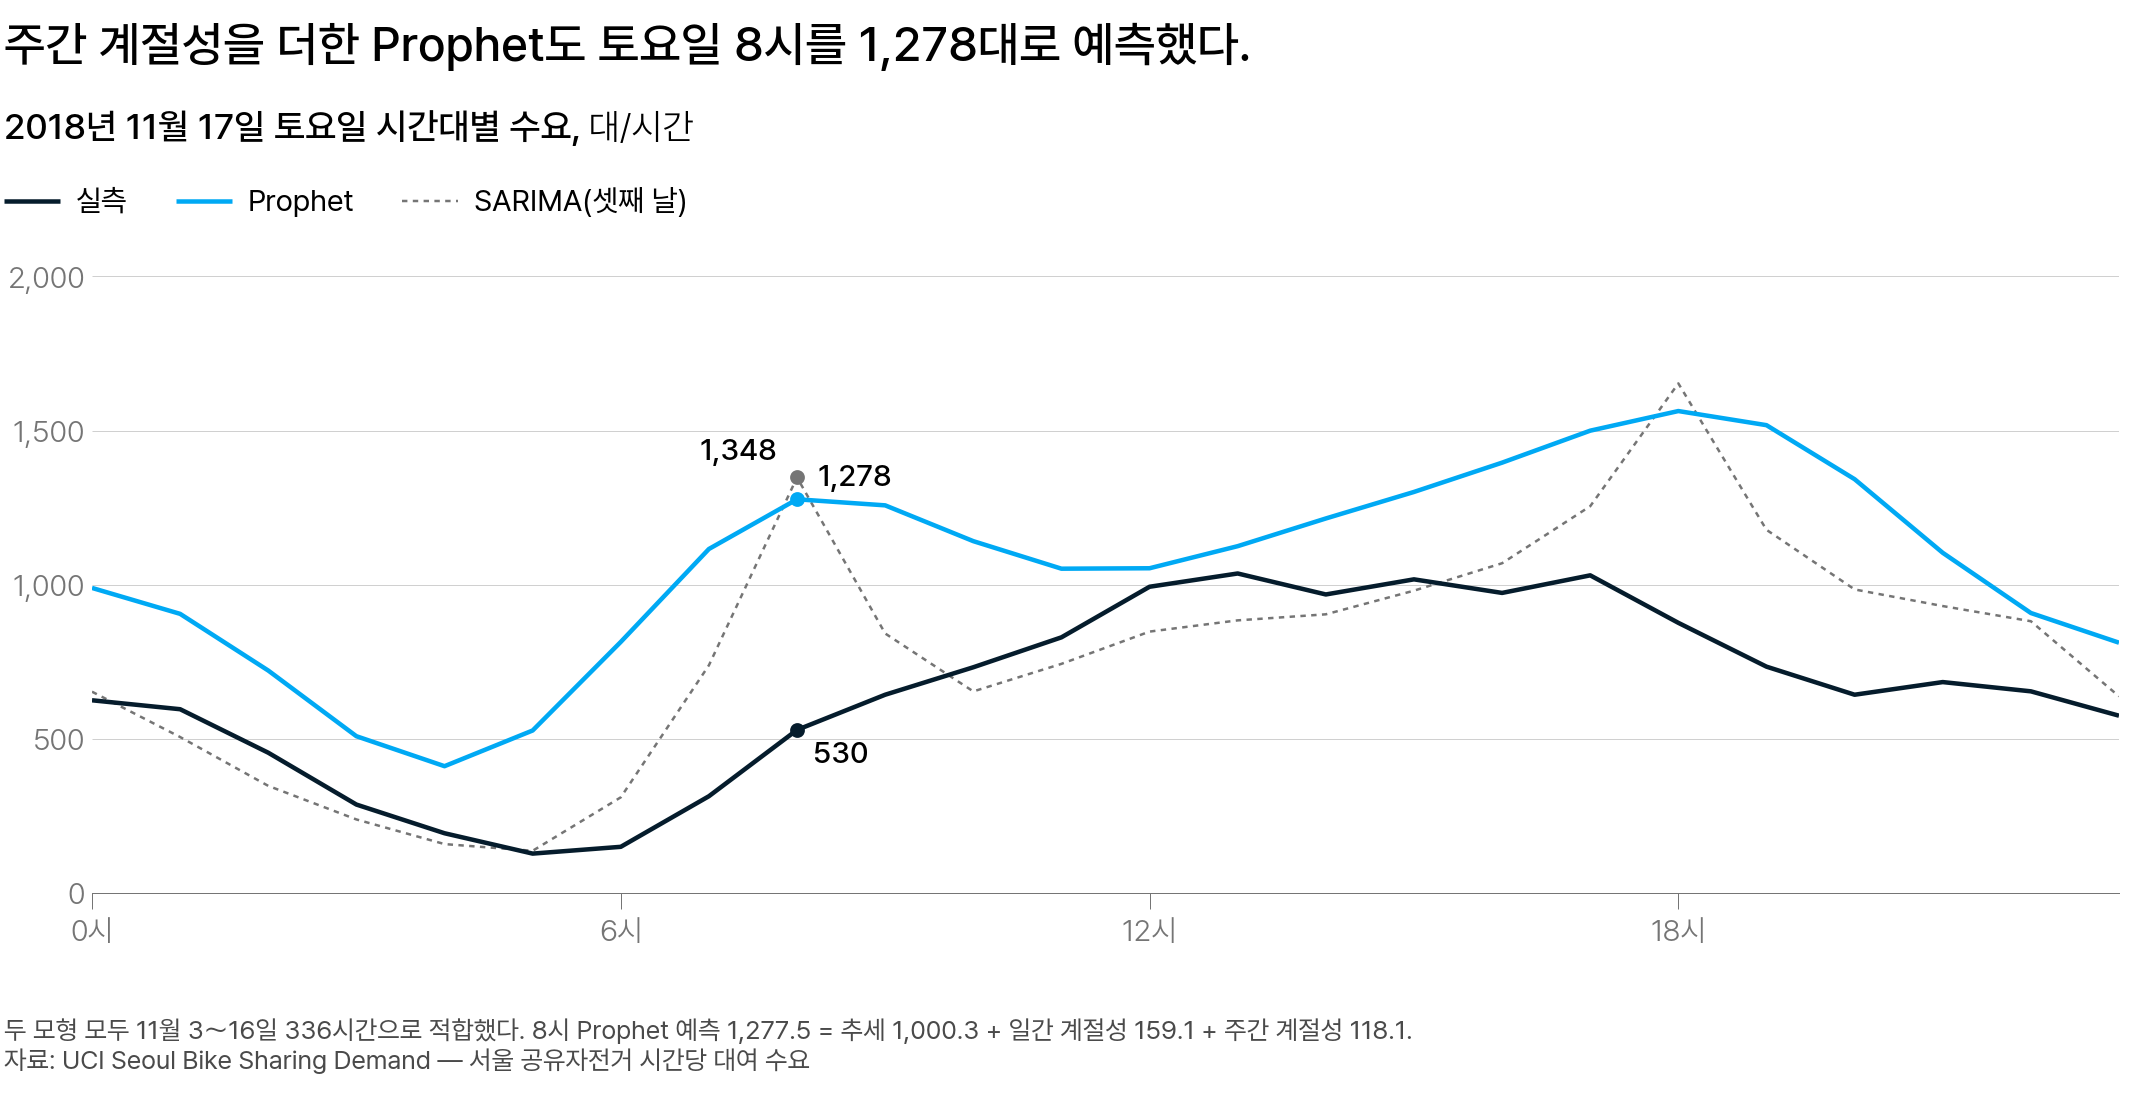

In [ ]:
# 도해 생성 코드는 LMS 에서만 실행됩니다

<p align="center"><em>▲ 11월 17일 토요일의 실측(남색)과 셋째 날 SARIMA(회색), Prophet(하늘색)의 24시간 예측. 8시에 실측 530대, SARIMA 1,348대, Prophet 1,278대이고, Prophet 은 하루 내내 실측보다 높다</em></p>

Prophet 이 하루 내내 높은 것은 추세가 1,000대 안팎으로 학습 336시간 평균 789대보다 높기 때문입니다. 비가 46mm 내린 8일은 하루 평균 수요가 72대였고, 추세도 이날 719대로 가장 낮았습니다. 그 뒤 수요가 다시 늘면서 추세는 13～16일에 하루 약 43대씩 커졌습니다. Prophet 은 이 마지막 기울기를 17일까지 그대로 이었습니다.

이 하루 RMSE 는 Prophet 이 465.9대로 가장 크고, SARIMA 295.4대, 계절 나이브 168 163.5대입니다. 추세의 높이는 학습 기간을 늘리면 달라집니다. 1,848시간 적합에서는 17일 8시 추세가 734.3대입니다. 요일마다 같은 하루 곡선을 더하는 점은 학습을 늘려도 그대로입니다.

8시가 특히 높은 까닭은 금요일과 토요일의 실측을 나란히 놓으면 보입니다.

| 시각 | 16일 금요일 실측 | 17일 토요일 실측 | 토요일에 더해야 할 값(토요일 − 금요일) |
|---|---|---|---|
| 8시 | 1,692대 | 530대 | −1,162대 |
| 13시 | 920대 | 1,037대 | +117대 |

토요일에 더해야 할 값이 8시에는 −1,162대, 13시에는 +117대로 방향이 반대입니다. 아래 그림의 왼쪽은 두 날의 실측이고, 오른쪽은 336시간 적합이 두 날에 더하는 계절성입니다.

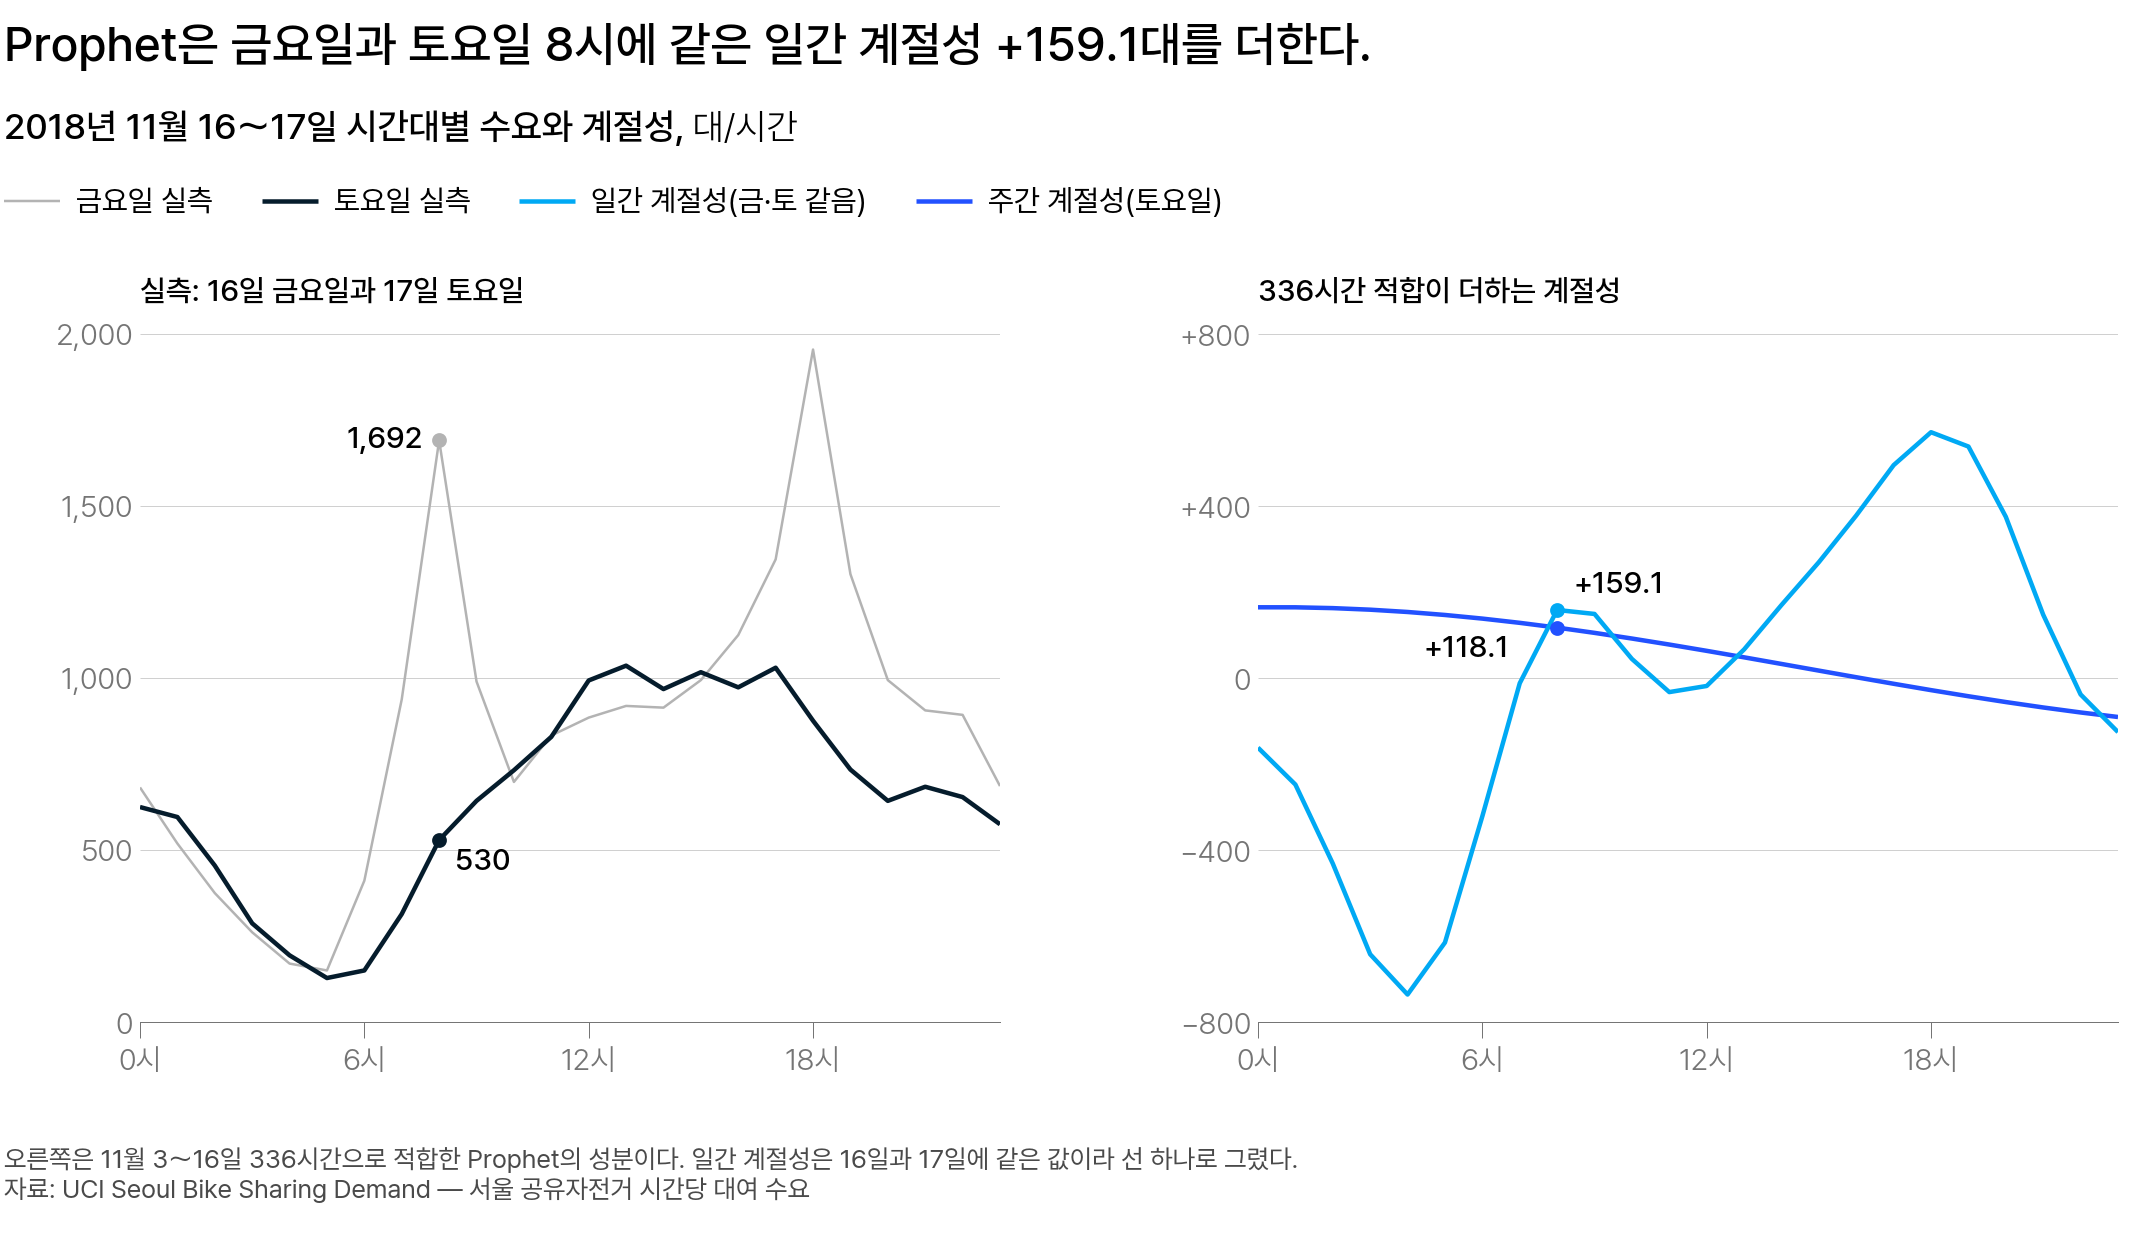

In [ ]:
# 도해 생성 코드는 LMS 에서만 실행됩니다

<p align="center"><em>▲ 16일 금요일과 17일 토요일의 실측(왼쪽)과 336시간 적합의 일간·주간 계절성(오른쪽). 일간 계절성은 두 날에 같은 곡선이고, 17일의 주간 계절성은 0시 +165대에서 23시 −90대로 내려간다</em></p>

두 그림 모두 가로축은 시각입니다. 세로축은 왼쪽이 수요, 오른쪽이 예측에 더하는 값입니다.

왼쪽에서 금요일은 8시 1,692대와 18시 1,956대에 수요가 많습니다. 토요일은 12～17시에 1,000대 안팎으로 많습니다.

오른쪽의 일간 계절성은 두 날에 똑같이 8시 +159.1대를 더합니다. 토요일 8시에도 금요일의 출근 수요만큼 더하는 셈입니다.

주간 계절성은 차수 3 이라 한 주 168시간에 많아야 세 번 오르내립니다. 그래서 하루 안에서는 완만하게만 움직입니다. 336시간 적합에서는 금요일 하루 동안 −210대에서 +164대로 오르고, 토요일 하루 동안 +165대에서 −90대로 내려갑니다. 토요일 8시는 내려가는 도중이라 아직 +118.1대입니다.

그래서 두 계절성을 더해도 8시만 1,000대 넘게 내리고 13시는 올리는 모양은 나오지 않습니다. 하루 곡선 자체를 요일에 따라 나눠야 합니다.

<details class="lms-extra"><summary>더 깊이 — 주간 계절성이 5시간 동안 바꿀 수 있는 양</summary>

17일의 주간 계절성은 한 시간에 많아야 15.5대 바뀝니다. 8시에서 13시까지 5시간이면 많아야 77.5대이고, 실제로는 +118.1대에서 +49.0대로 69.1대 내려갔습니다.

토요일에 필요한 변화는 8시 −1,162대에서 13시 +117대로, 1,279대를 올리는 것입니다. 주간 계절성이 5시간에 바꿀 수 있는 양은 이 크기에 크게 못 미치고, 17일에는 방향도 반대였습니다.

</details>

#### 하루 곡선을 평일과 주말로 나누는 조건부 계절성

일간 계절성을 평일 곡선과 주말 곡선으로 나눈 구성을 **조건부 계절성(conditional seasonality)** 이라 합니다. 두 곡선에는 그날이 평일인지 주말인지에 따라 1 이나 0 을 곱합니다.

$$
\begin{aligned}
\hat{y}(t) = g(t) &+ {\color{#1f6feb}s_{\text{평일}}(t)\,\mathbf{1}[t \in \text{평일}]} \\
&+ {\color{#1f6feb}s_{\text{주말}}(t)\,\mathbf{1}[t \in \text{주말}]} + s_{\text{주간}}(t)
\end{aligned}
$$

기본 구성의 $s_{\text{일간}}(t)$ 하나가 파란 두 항으로 바뀌었습니다.

- $s_{\text{평일}}(t)$ : 평일 곡선. 평일 시각으로만 정하는 하루 곡선입니다
- $s_{\text{주말}}(t)$ : 주말 곡선. 주말 시각으로만 정하는 하루 곡선입니다
- $s_{\text{주간}}(t)$ : 주간 계절성. 기본 구성과 같은 항이고, 요일마다 하루 대여량이 조금씩 다른 것만 맡습니다
- $\mathbf{1}[t \in \text{평일}]$ : 추세 식의 $\mathbf{1}[t \ge s_1]$ 과 같은 표시함수입니다. 괄호 안의 조건이 맞으면 1, 아니면 0 입니다

$$
\mathbf{1}[t \in \text{평일}] =
\begin{cases}
1 & \text{월요일～금요일} \\
0 & \text{토요일·일요일}
\end{cases}
$$

$\mathbf{1}[t \in \text{주말}]$ 은 반대로 토요일·일요일에 1 입니다. 1 을 곱한 곡선은 그대로 더해지고, 0 을 곱한 곡선은 0 이 되어 빠집니다.

| 시각 | $\mathbf{1}[t \in \text{평일}]$ | $\mathbf{1}[t \in \text{주말}]$ | 더해지는 하루 곡선의 값 |
|---|---|---|---|
| 16일 금요일 8시 | 1 | 0 | 평일 곡선의 8시 값 |
| 17일 토요일 8시 | 0 | 1 | 주말 곡선의 8시 값 |

주말 곡선은 주말 시각으로만 정해집니다. 336시간에는 주말 시각이 96개뿐이고, 1,848시간(9월 1일～11월 16일)에는 528개입니다. 그래서 두 구성은 1,848시간으로 적합해 견줍니다.

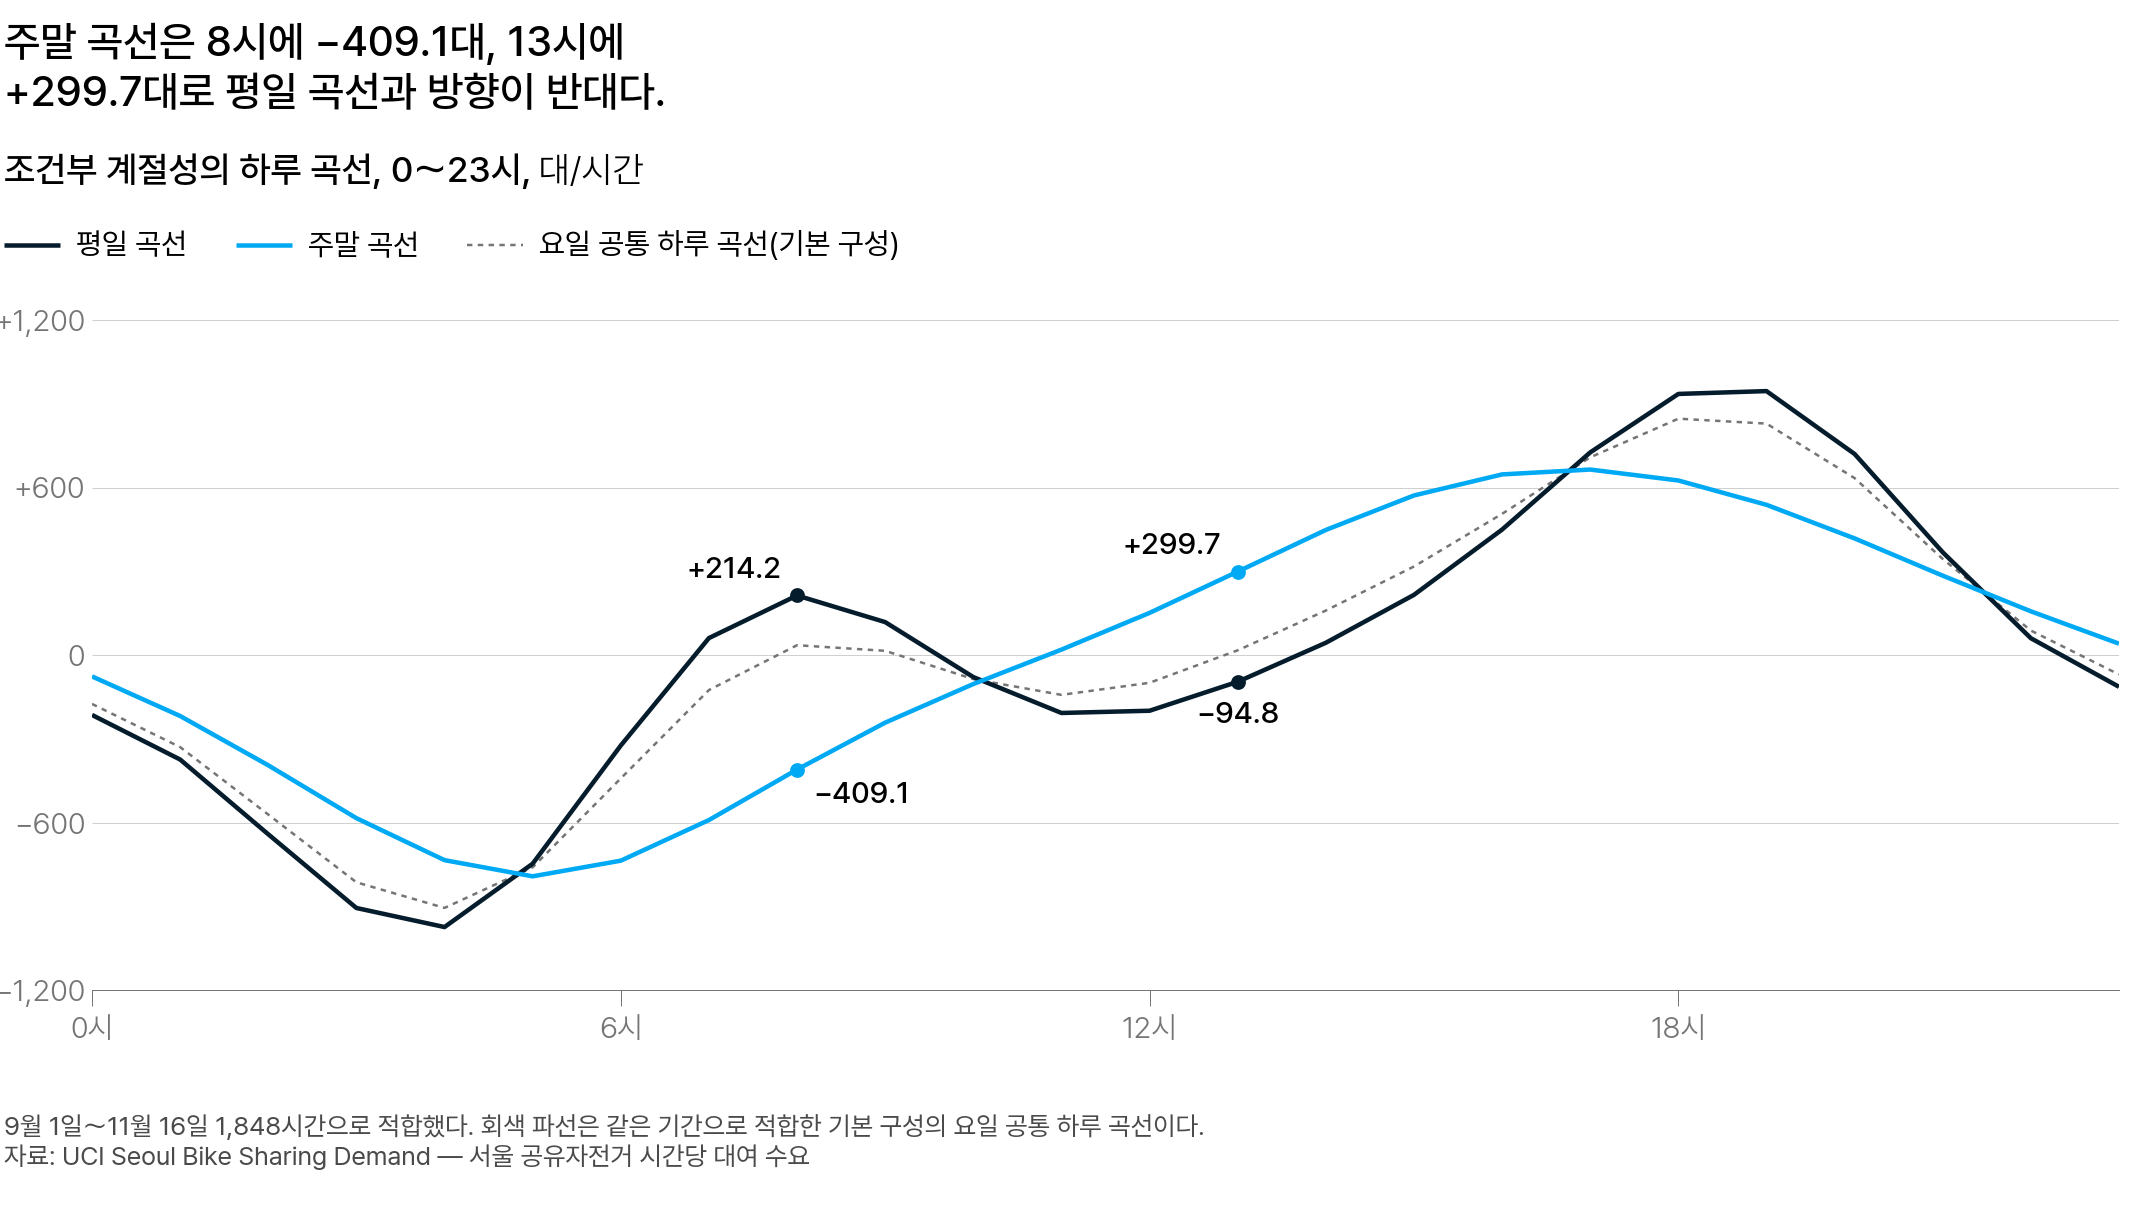

In [ ]:
# 도해 생성 코드는 LMS 에서만 실행됩니다

<p align="center"><em>▲ 1,848시간 적합의 평일 곡선(남색)과 주말 곡선(하늘색), 기본 구성의 요일 공통 하루 곡선(회색 파선). 8시에 평일 곡선은 +214.2대, 주말 곡선은 −409.1대다</em></p>

가로축은 시각, 세로축은 예측에 더하는 값입니다.

학습을 1,848시간으로 늘리면 성분이 모두 다시 추정됩니다. 기본 구성에서는 17일 8시 추세가 1,000.3대에서 734.3대로 바뀝니다. 요일 공통 하루 곡선의 8시 값도 +159.1대에서 +36.2대로 바뀝니다. 금요일과 토요일에 같은 값을 더한다는 점은 그대로입니다.

나누기 전의 요일 공통 하루 곡선은 8시에 모든 요일에 +36.2대를 더합니다. 나눈 뒤에는 평일 곡선이 8시 +214.2대, 13시 −94.8대입니다. 주말 곡선은 8시 −409.1대, 13시 +299.7대로 반대 방향입니다.

조건부 계절성도 같은 1,848시간으로 따로 적합하므로 추세가 732.8대로 조금 다릅니다. 두 구성의 17일 8시(실측 530대) 예측을 항별로 나누면 이렇습니다.

$$
\begin{aligned}
\text{기본 구성} &: \ \underset{\text{추세}}{734.3} + \underset{\text{일간}}{36.2} - \underset{\text{주간}}{10.9} \approx 760 \\
\text{조건부 계절성} &: \ \underset{\text{추세}}{732.8} - \underset{\text{주말 곡선}}{409.1} - \underset{\text{주간}}{15.9} \approx 308
\end{aligned}
$$

추세는 734.3대와 732.8대로 거의 같고, 주간 계절성도 −10.9대, −15.9대로 작습니다. 8시 예측을 바꾼 항은 일간 계절성 항입니다.

조건부 계절성은 8시를 약 308대로 낮췄고, 이번에는 실측보다 222대 적습니다. 어느 구성이 나은지는 한 시각이 아니라 검증 168시간의 오차로 판단합니다.

그래서 하루의 모양이 요일마다 다르면 조건부 계절성으로 하루 곡선을 나눕니다. Prophet 에서는 `add_seasonality` 의 `condition_name` 에 평일·주말을 나타내는 참거짓 열의 이름을 적습니다.

#### 조건부 계절성은 검증 168시간의 오차를 줄이는가

1,848시간으로 적합한 두 구성으로 11월 17～23일 검증 168시간을 예측해 견줍니다. 두 구성 모두 휴일 효과를 포함합니다.

| 선택지 | 특징 | 이런 경우에 쓴다 | 서울 공유자전거 11월 17일 8시(실측 530대) | 검증 168시간 RMSE |
|---|---|---|---|---|
| 요일 공통 하루 곡선 하나(기본값 $N = 4$) | 요일 차이는 완만한 주간 계절성만 맡음, 계수 8개 | 수요가 많은 시각이 요일마다 같을 때 | 8시 기여분 +36.2, 예측 759.5대(실측보다 230대 많음) | 310.34 |
| 조건부 계절성(`condition_name`) | 하루 곡선 2개(계수 16개). 주말 곡선은 학습 구간의 주말 528시간으로만 정함 | 수요가 많은 시각이 요일에 따라 다를 때(16일 금요일은 8시·18시, 17일 토요일은 12～17시) | 8시 기여분 −409.1, 예측 307.8대(실측보다 222대 적음) | 274.78 |

두 RMSE 는 뒤의 예측 원점 5개 표에서 11월 16일 행의 값과 같습니다.

8시 한 시각만 보면 넘치던 예측이 모자라게 바뀌었을 뿐 빗나간 크기는 비슷하고, 나아진 것은 168시간 전체의 오차입니다. 그래서 수요가 많은 시각이 요일마다 다르면 조건부 계절성을 후보로 견줍니다. 다만 이 구성은 이 검증 168시간을 보고 고른 것이라 이 기간 점수가 실제보다 좋게 나올 수 있습니다. 그래서 운영 예측에 쓸지는 아직 쓰지 않은 테스트 구간(11월 24～30일)에서 한 번 더 채점해 정합니다.

<div class="lms-summary">

**정리**

평일과 주말의 하루 모양이 다르면 일간 계절성을 평일·주말로 나눈 조건부 계절성을 후보로 둡니다. 336시간 적합의 요일 공통 하루 곡선은 금요일과 토요일 8시에 같은 +159.1대를 더합니다. 그래서 토요일 8시를 1,277.5대로 예측했습니다. 주말 시각이 528개인 1,848시간 적합에서 조건부 계절성은 한 주 검증 RMSE 를 310.34 에서 274.78 로 낮췄습니다.

- 학습 표와 예측 표에 `weekday`·`weekend` 참거짓 열을 만들고, `daily_seasonality=False` 로 둔 뒤 `add_seasonality('daily_weekend', period=1, fourier_order=4, condition_name='weekend')` 처럼 하루 곡선을 둘 둡니다
- 나눌지는 평일과 주말의 시각별 평균을 두 선으로 그려 보고 정합니다(11월 17일 SARIMA 예측 그림의 회색 두 선)
- 일간 계절성의 푸리에 차수는 상한(하루 12) 안에서 학습 밖 오차로 견줍니다. 서울은 차수 10 이 후보입니다(원점 5개 평균 358.41)

더하는 식에서 주간 계절성은 하루 안에서 완만하게만 움직이므로, 하루의 모양이 요일마다 다르면 하루 곡선을 나눕니다.

</div>

> **[문제] 연간 계절성의 푸리에 차수**
>
> 주간 계절성은 앞에서 $N = 3$ 에 최대 오차가 0.000 이 되어 상한에 도달했습니다. 일간 계절성은 상한 12 를 넘긴 20·40 에서도 검증 RMSE 가 280.0 에 머물렀습니다. 이번에는 연간 계절성의 `fourier_order` 를 기본값 10 에서 40 으로 올린다고 해 봅시다. 참고로 한 해에 시점이 12개인 호주 외식 지출 월별 자료에서는 푸리에 차수를 1 에서 6 으로 키울수록 AICc 가 줄었습니다. AICc 는 학습 표본 안의 적합도에 계수 개수만큼 페널티를 더한 점수로, 둘째 날 AIC 와 같은 종류입니다. ⑴ 연간 계절성에는 왜 상한이 그렇게 늦게 오는지 한 주기 안의 시점 수로 설명하고 ⑵ AICc 가 감소하는데도 40 을 개선이라 부르기 어려운 이유를 두세 문장으로 적어 보세요.

## 6. 휴일 효과 h(t)와 관측이 적은 계수의 축소

휴일을 모형에 어떻게 더하고, 추정된 휴일 계수를 얼마나 믿어야 할까요?

설 연휴는 음력이라 양력 날짜가 해마다 바뀌어, 정해진 간격으로 되풀이되는 사인·코사인 항으로 나타낼 수 없습니다.

**휴일 효과 $h(t)$** 는 지정한 날에만 그 이벤트의 계수를 더하는 항입니다.

$$
h(t) = \sum_{i} \kappa_i \, \mathbf{1}[t \in D_i]
$$

- $D_i$ : $i$ 번째 이벤트(설, 추석, 광복절 …)의 날짜 목록입니다
- $\mathbf{1}[t \in D_i]$ : 그날이 목록에 있으면 1, 아니면 0 인 표시함수입니다
- $\kappa_i$ : 그 이벤트의 **휴일 계수**, 곧 그날 수요가 평소와 얼마나 다른지이고 자료가 정합니다

설 당일만 지정하면 설 당일에는 $h(t) = \kappa_{\text{설}}$ 이고 설이 아닌 날에는 0 입니다. 휴일 항 없이 적합한 일 수요에서 설 당일 2월 16일의 오차항은 −4,040대/일이었고, 휴일 항을 두면 이 오차가 $\kappa_{\text{설}}$ 로 옮겨 갈 수 있습니다.

날짜 목록 $D_i$ 는 **휴일 데이터프레임(`holidays`)** 에 적습니다.

| 열 | 내용 | 설 한 행의 예 |
|---|---|---|
| `holiday` | 이벤트 이름(같은 이름끼리 효과 하나를 공유) | 설 |
| `ds` | 그 이벤트의 날짜(과거와 미래 모두) | 2018-02-16 |

`lower_window`·`upper_window` 는 휴일 효과를 며칠 전부터 며칠 뒤까지 볼지 정하는 날짜 범위입니다. 설 한 행에 −1 과 +1 을 적으면 2월 15·16·17일이 묶이고, 날마다 계수가 하나씩 3개 생깁니다.

서울은 설 연휴 사흘이 한 주 전 같은 요일의 62%·41%·70% 로 앞뒤 날도 낮았습니다. 다만 계수가 날마다 따로라 계수마다 관측은 여전히 한 번입니다. 그래서 시간당 자료로 적합할 때는 `lower_window`·`upper_window` 를 모두 0 으로 두어 공휴일 당일만 휴일로 지정했습니다.

<details class="lms-extra"><summary>더 깊이 — 성분 화면의 휴일 그림과 주간 계절성 그림</summary>

<img src="https://assets.mbrenndoerfer.com/_optimized/notebooks/prophet_files/prophet-components-trend-seasonality-holidays-1920w.webp" width="640" height="903"/>
<p align="center"><em>▲ 적합이 끝난 Prophet 모형의 성분 화면. 위에서부터 추세·휴일·요일·연중·사용자 정의 월간이고, 위에서 둘째 그림의 휴일은 1년에 며칠만 값을 갖는 반면 셋째 그림의 주간 계절성은 매주 부드럽게 오르내린다 (출처: Marcel Brenndoerfer, "Prophet: Time Series Forecasting")</em></p>

위에서 둘째 그림이 $h(t)$ 입니다. 예시 계열이라 세로축 값은 임의 단위로 읽고, 여기에서 볼 것은 크기가 아니라 횟수입니다. 요일은 1년에 52번 되풀이되고 휴일은 며칠뿐입니다.

</details>

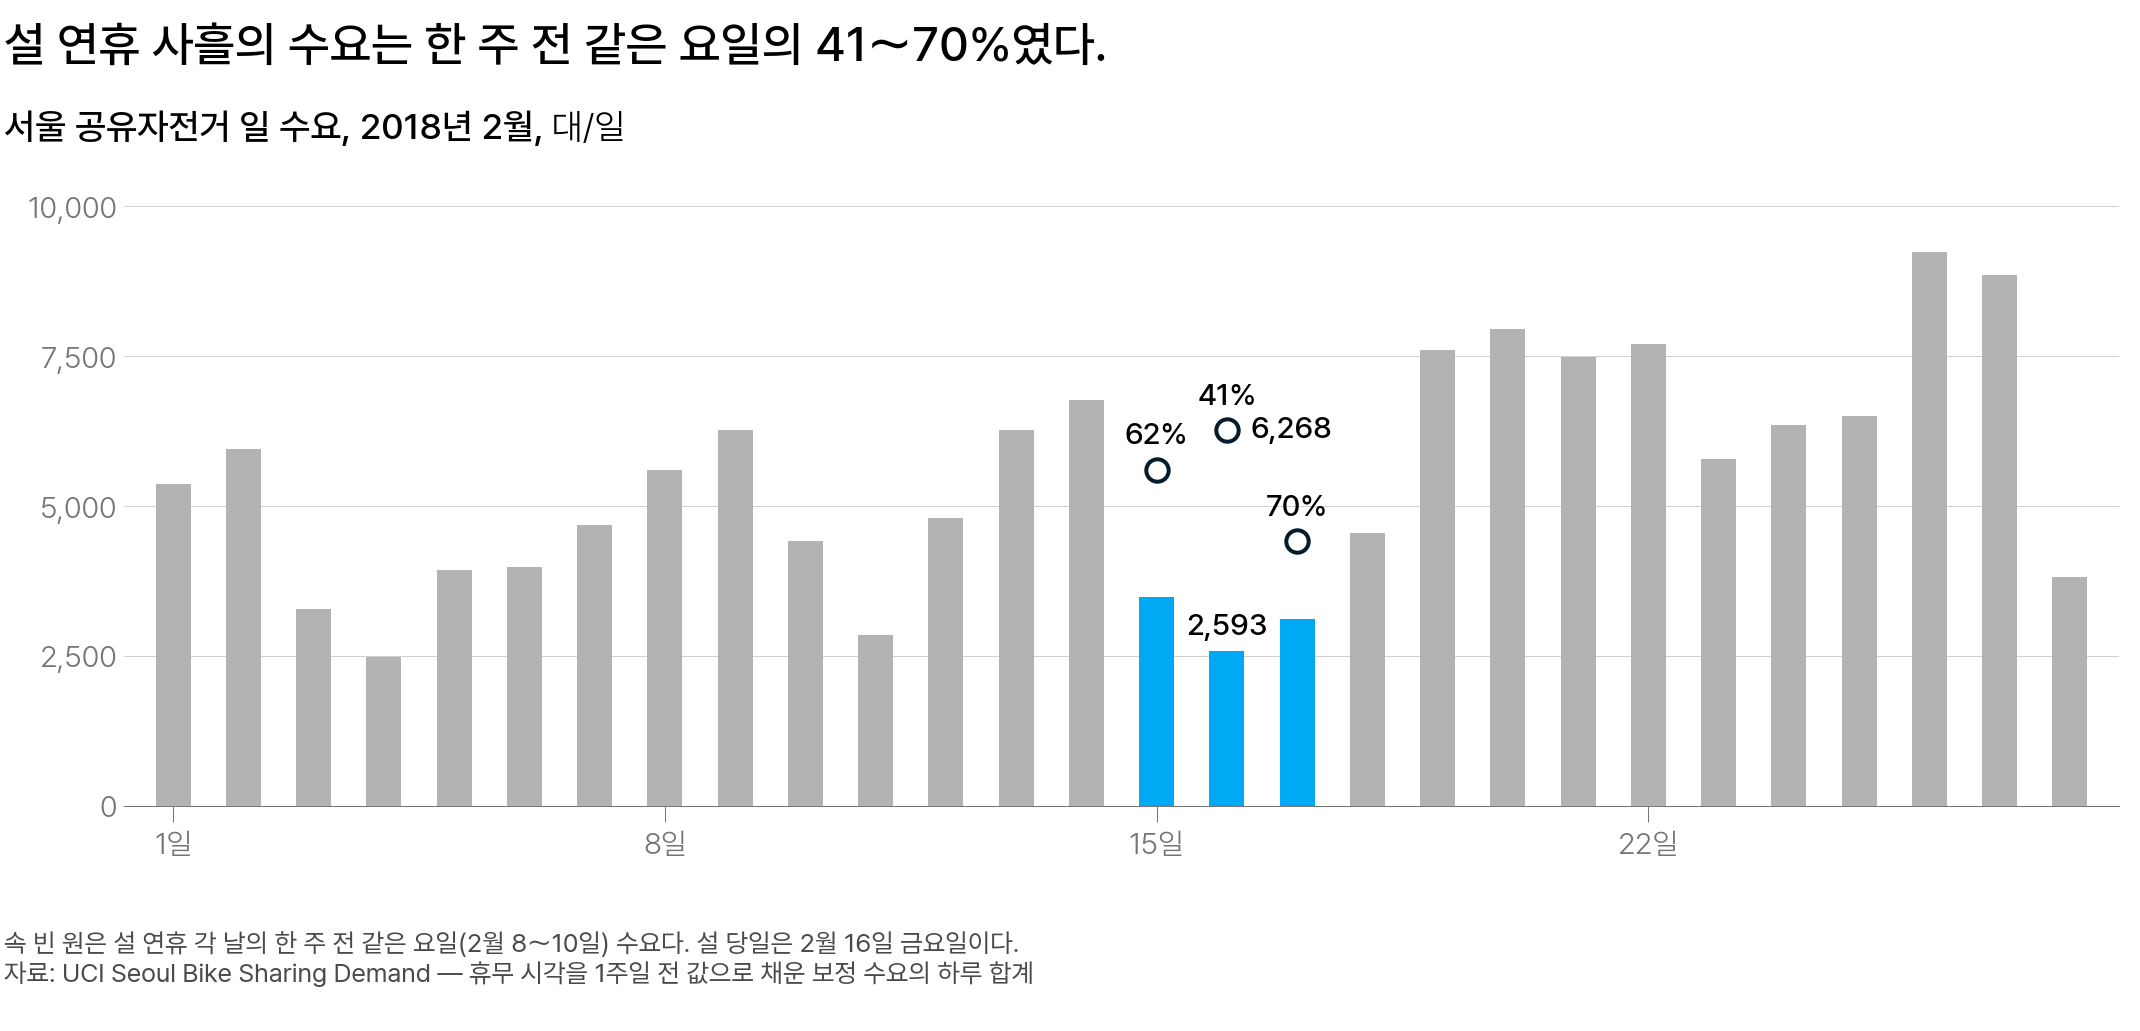

In [ ]:
# 도해 생성 코드는 LMS 에서만 실행됩니다

<p align="center"><em>▲ 2018년 2월 서울 일 수요. 하늘색이 설 연휴 15～17일이고, 속 빈 원은 한 주 전 같은 요일의 값이다. 연휴 사흘은 그 값의 62%·41%·70%였다</em></p>

설 당일 수요가 한 주 전 금요일의 41% 로 줄었다는 크기를 설 계수 하나로 얼마나 믿을 수 있을까요?

## 왜 휴일 계수는 관측 1회로 정하기 어려운가

설 당일의 −4,040대/일이 설 때문인지 그날의 우연인지는 한 번의 관측으로 구분하기 어렵습니다. 1년 오차항의 표준편차가 약 5,100대/일이라, 보통 날도 이만큼 오르내리기 때문입니다. 요일은 1년에 52번 나오지만 휴일은 며칠뿐입니다. 아래 셀은 1년치 공휴일 수와 설·추석 당일의 비율을 계산합니다.

In [ ]:
# 1년치에서 공휴일은 며칠이고, 설·추석 당일은 한 주 전 같은 요일의 몇 %였나
import pandas as pd

try:
    raw = load_csv("datasets/SeoulBikeData.csv")            # LMS 에서는 LMS 가 올려 둔 자료를 이 함수로 읽는다
except NameError:                                           # Colab·내 컴퓨터에는 이 함수가 없어 UCI 원본 주소에서 받는다
    SRC = ("https://archive.ics.uci.edu/static/public/560/"
           "seoul+bike+sharing+demand.zip")
    raw = pd.read_csv(SRC, encoding="cp1252", compression="zip")
raw.columns = ["date", "count", "hour", "temp", "humidity", "wind", "visibility",
               "dewpoint", "solar", "rain", "snow", "season", "holiday", "functioning"]
raw.index = pd.to_datetime(raw["date"], format="%d/%m/%Y") + pd.to_timedelta(raw["hour"], unit="h")
raw = raw.sort_index()
day = raw["count"].resample("D").sum()                     # 시간당 수요 24개를 더한 일 수요
hol_days = raw.index[raw["holiday"].eq("Holiday")].normalize().unique()
print(f"1년치 공휴일 {len(hol_days)}일, 설과 추석은 1년치 안에서 한 번씩만 나온다")
print(f"당일 수요 ÷ 한 주 전 같은 요일: 설 {day['2018-02-16'] / day['2018-02-09']:.0%}({day['2018-02-16']:,}÷{day['2018-02-09']:,}대), "
      f"추석 {day['2018-09-24'] / day['2018-09-17']:.0%}({day['2018-09-24']:,}÷{day['2018-09-17']:,}대)")
assert len(hol_days) == 18 and day["2018-02-16"] == 2593 and day["2018-02-09"] == 6268
assert day["2018-09-24"] == 17259 and day["2018-09-17"] == 30290

달력을 보고 나누면 공휴일 18일은 사건 14개이고(설 연휴 3일과 추석 연휴 3일이 한 사건씩), 사건마다 1년치 안에서 1번 관측됩니다.

관측이 적을수록 추정값은 표본마다 크게 달라집니다. 추정값의 표준편차를 **표준오차(standard error)** 라 부릅니다. 휴일 계수는 휴일 날 평균에서 평소 날 평균을 뺀 값이라 두 평균의 흔들림이 함께 들어가고, 평균은 모은 날이 적을수록 더 흔들립니다.

$$
\mathrm{SE} = \sigma \sqrt{1/n_{\mathrm{hol}} + 1/n_{\mathrm{base}}}
$$

- $\sigma$ : 오차항의 표준편차
- $n_{\mathrm{hol}}$ : 그 계수 하나에 해당하는 휴일 날 수(설 사흘을 묶어도 계수마다 1일)
- $n_{\mathrm{base}}$ : 휴일이 아닌 날 수

아래 모의실험은 휴일이 아닌 날 60일과 휴일 1일 또는 5일에 진짜 효과 +300 을 심어 두고 2,000번 다시 추정합니다.

In [ ]:
# 휴일 효과 +300을 주입한 뒤 회수해 보기 - 관측 1회일 때와 5회일 때
import numpy as np

rng = np.random.default_rng(42)
TRUE = 300.0                      # 우리가 심어 둔 진짜 휴일 효과

for n_hol in (1, 5):
    est = []
    for _ in range(2000):         # 같은 상황을 2000번 되풀이해 추정값이 표본마다 얼마나 달라지는지 본다
        base = rng.normal(1000, 120, 60)          # 휴일이 아닌 날 60일
        hol = rng.normal(1000, 120, n_hol) + TRUE  # 휴일 n_hol일
        est.append(hol.mean() - base.mean())
    est = np.array(est)
    print(f"휴일 관측 {n_hol}회 → 추정 평균 {est.mean():6.1f} · 표준오차(추정값의 표준편차) {est.std():5.1f} · "
          f"추정값 90% 범위 {np.percentile(est, 5):.0f}부터 {np.percentile(est, 95):.0f}까지")

| 관측 횟수 | 추정값 90% 범위(참값 300) |
|---|---|
| 1회 | 101～493 |
| 5회 | 202～392 |

서울 설이면 휴일이 아닌 날이 347일이라 표준오차는 $5{,}100 \times \sqrt{1 + 1/347} \approx 5{,}110$대/일이고, 설 당일 오차항 −4,040 의 크기보다 큽니다.

**그래서** 「휴일 계수가 크게 나왔다」와 「그 휴일의 효과가 크다고 데이터로 확인되었다」는 다른 말입니다.

관측 수를 늘리는 방법 하나는 효과가 비슷한 사건을 한 이름으로 묶는 것입니다.

| 선택지 | 특징 | 이런 경우에 쓴다 | 서울 공유자전거에서 |
|---|---|---|---|
| 이름별(설·추석 따로) | 사건마다 계수 하나, 관측 1회 | 효과 크기가 사건마다 다르고 여러 해 자료가 있을 때 | 설 당일 41%, 추석 당일 57% |
| 한 이름(「공휴일」) | 관측이 늘어 덜 흔들림, 사건별 차이는 평균 하나로 | 사건마다 관측이 1회뿐일 때 | 학습 구간의 공휴일 5일(추석 연휴 3일·개천절·한글날)을 계수 하나로 묶음 |

그래서 사건마다 관측이 한 번뿐인 1년치 자료에서는 비슷한 휴일을 한 이름으로 묶습니다.

## 관측이 적은 휴일 계수를 줄이는 `holidays_prior_scale`

설 계수를 공휴일로 묶지 않고 따로 둔다면, 한 번 본 값을 얼마나 믿어야 할까요?

**`holidays_prior_scale`** 은 휴일 계수가 0 에서 얼마나 멀어져도 되는지 정하는 값입니다. 기본값 10 은 거의 막지 않고, 작게 둘수록 계수를 0 쪽으로 당깁니다. `changepoint_prior_scale` 이 추세의 변화량 $\delta_j$ 에 하는 일을 휴일 계수에 합니다. Prophet [공식 문서](https://facebook.github.io/prophet/docs/seasonality,_holiday_effects,_and_regressors.html)도 기본값 10 은 규제(regularization), 곧 계수를 0 쪽으로 당기는 일이 거의 없다고 적습니다.

설 당일 계수 하나만 떼어 보면 휴일 항은 이렇습니다.

$$
h(t) = \kappa_{\text{설}} \times \mathbf{1}[t \in D_{\text{설}}]
$$

- $\mathbf{1}[t \in D_{\text{설}}]$ : 그날이 설 당일(2018년 2월 16일)이면 1, 아니면 0 인 표시함수입니다
- $\kappa_{\text{설}}$ : 설 계수, 곧 설 당일 예측에 더하는 값(대/일)입니다

서울 일 수요 1년치를 기본값 10 으로 적합하면 $\kappa_{\text{설}} = -4{,}686$ 이라, 설 당일 예측에서 4,686대/일을 뺍니다. 앞의 설 당일 오차항 −4,040 보다 큰 까닭은 이렇습니다. 휴일 항이 없을 때는 설 연휴의 낮은 수요가 추세와 계절성을 조금 낮췄습니다. 휴일 항이 그 빗나감을 맡자 설 당일의 추세와 계절성의 합이 6,633대에서 7,273대로 640대 커졌습니다. 설 계수는 그만큼 더 커졌습니다.

예를 들어 설 당일 실제 수요가 100대, 추세와 계절성만의 예측이 1,100대라고 해 봅니다. 아무 제한이 없으면 설 계수는 그 차이인 약 −1,000 이 됩니다.

앞에서 본 것처럼 1년치에는 설이 한 번뿐입니다. 이 −1,000 이 설마다 되풀이되는 효과인지, 그해 설의 날씨·사건 때문인지 알 수 없습니다. 그래서 한 번 본 값을 얼마나 믿을지 따로 정합니다.

**벌점(penalty)** 은 계수가 0 에서 멀수록 커지도록 오차에 더하는 값입니다. 적합은 오차와 벌점을 더한 값이 가장 작은 계수를 찾습니다.

$$
\text{줄이는 값} = \text{오차 제곱합} + \lambda \times \kappa_{\text{설}}^{2}
$$

- 오차 제곱합: 날마다 실측과 예측의 차이를 제곱해 더한 값입니다. 앞의 예에서는 설 계수가 −1,000 일 때 가장 작습니다
- $\kappa_{\text{설}}^{2}$ : 설 계수의 벌점입니다. 계수가 0 에서 멀수록 커집니다
- $\lambda$ : 벌점에 곱하는 무게입니다. 클수록 계수가 0 쪽으로 갑니다

앞의 예에 대입해 봅니다. 설 하루의 오차는 $100 - (1{,}100 + \kappa_{\text{설}})$ 이라, 줄이는 값은 $(\kappa_{\text{설}} + 1{,}000)^2 + \lambda \times \kappa_{\text{설}}^{2}$ 입니다. $\lambda = 9$ 로 두고 계수 셋을 대입하면 이렇습니다.

| 설 계수 $\kappa_{\text{설}}$ | 오차 제곱 $(\kappa_{\text{설}} + 1{,}000)^2$ | 벌점 $9 \times \kappa_{\text{설}}^{2}$ | 합 |
|---|---|---|---|
| −1,000 | 0 | 9,000,000 | 9,000,000 |
| −100 | 810,000 | 90,000 | 900,000 |
| 0 | 1,000,000 | 0 | 1,000,000 |

합이 가장 작은 계수는 −100 이고, 이때 설 당일 오차항은 $100 - (1{,}100 - 100) = -900$ 입니다. 합이 가장 작은 계수는 $-1{,}000 \div (1 + \lambda)$ 라, $\lambda = 0$ 이면 −1,000 이고 $\lambda = 9$ 이면 −100 입니다.

`holidays_prior_scale` 은 $\lambda$ 와 방향이 반대입니다. 값을 작게 둘수록 벌점이 커져 계수가 0 쪽으로 갑니다. 넷째 날 실습의 릿지 회귀(ridge regression)도 계수에 이런 벌점을 더합니다.

Prophet 은 벌점 대신 「설 계수는 0 근처일 것」이라는 정규분포를 사전분포(prior)로 두고, 그 표준편차를 `holidays_prior_scale` 로 정합니다. 표준편차가 작을수록 0 에서 먼 계수를 드물게 보므로 결과는 벌점과 같은 방향입니다. 이 표준편차는 수요를 학습 자료의 최댓값(서울 일 수요 36,149대)으로 나눈 단위입니다. 그래서 기본값 10 은 최댓값의 10배만큼 넓어 거의 막지 않습니다.

서울 일 수요 1년치로 설 연휴 사흘을 지정하고 `holidays_prior_scale` 만 바꿔 적합했습니다.

| `holidays_prior_scale` | 설 당일 계수 $\kappa_{\text{설}}$(대/일) | 설 당일 오차항(대/일) |
|---|---|---|
| 10(기본값) | −4,686 | +6 |
| 0.1 | −1,420 | −2,818 |
| 0.01 | −20 | −4,037 |

이 표는 반복 계산을 끝까지 이어 가는 `m.fit(df, algorithm="Newton")` 으로 적합한 값입니다. 옵션 없이 `m.fit(df)` 로 적합하면 계산이 일찍 멈춰, 기본값 10 에서도 설 계수가 약 −500 으로 나옵니다.

10 에서는 설 당일 오차항이 +6대/일이라, 설 한 번의 빗나감을 거의 모두 계수가 맡았습니다. 0.01 에서는 계수가 −20 뿐입니다. 앞의 예와 달리 실제 적합에서는 추세와 계절성도 함께 움직입니다. 설 당일의 추세와 계절성의 합이 10 일 때의 7,273대에서 약 6,650대로 내려가고, 나머지 −4,037 이 그날 오차항에 남습니다.

$$
\underbrace{-20}_{\text{설 계수}} + \underbrace{6{,}650}_{\text{추세와 계절성}} + \underbrace{(-4{,}037)}_{\text{오차항}} \approx 2{,}593
$$

셋을 더하면 설 당일 실측 2,593대입니다. 빗나감을 계수와 오차항이 나눠 맡는 방향은 앞의 예에서 −1,000 을 계수 −100 과 오차항 −900 으로 나눈 것과 같습니다.

설정값 하나로 설 계수가 −4,686 에서 −20 까지 바뀝니다. 어느 값이 다음 설에 맞는지는 설이 든 기간을 학습에서 빼 두고 그 기간의 오차로 견줘야 압니다. 그런데 1년치에는 설이 한 번뿐이라 그렇게 견줄 수 없습니다.

10 은 한 번 본 −4,686 을 그대로 쓰는 쪽이고, 0.01 은 설 효과를 거의 없음(−20)으로 보는 쪽입니다. 검증으로 고를 수 없으면 기본값에서 다른 값으로 옮길 근거도 없습니다. 그래서 임의의 값을 새로 정하지 않고 기본값 10 을 둡니다. 10 이 맞다고 확인해서가 아니라, 다른 값을 고를 근거가 없어서입니다.

계수를 믿기 어렵다는 점은 보고 방식으로 다룹니다. 설 계수를 효과 크기로 읽지 않고, 보고해야 하면 10 과 0.01 의 값(−4,686, −20)을 함께 적습니다. 비슷한 휴일이 여럿이면 앞에서처럼 한 이름으로 묶어 관측을 늘립니다. 설이 두 번 든 자료가 생기면 앞 해로 학습해 다음 해 설 무렵의 오차로 다시 고릅니다.

<details class="lms-extra"><summary>더 깊이 — 옵션 없이 적합하면 설 계수가 약 −500 인 까닭</summary>

적합은 계수를 조금씩 고쳐 가며 오차를 줄이는 반복 계산입니다. 옵션 없이 `m.fit(df)` 로 적합하면, 기본 계산 방식은 한 번 고쳐도 오차가 거의 줄지 않을 때 거기서 멈춥니다. 설 당일의 제곱 오차는 1년 합의 1% 도 안 되어, 기본값 10 에서도 설 계수가 약 −500 에 머뭅니다. 설 계수로 읽을 값은 끝까지 계산한 −4,686 입니다.

</details>

<div class="lms-summary">

**정리**

1년치에서 나온 휴일 계수는 효과 크기로 보고하지 않습니다. 설은 1년치에 한 번뿐이라 설 계수의 표준오차(약 5,110대/일)가 설 당일 오차항(−4,040대/일)보다 큽니다.

`holidays_prior_scale` 은 기본값 10 으로 둡니다. 설이 든 기간을 학습에서 빼 두고 값을 고를 수 없어, 기본값에서 다른 값으로 옮길 근거가 없기 때문입니다.

- `holiday`·`ds` 두 열의 표에 과거와 미래의 휴일 날짜를 모두 적어 `Prophet(holidays=...)` 에 전달합니다
- 사건마다 관측이 한 번뿐이면 비슷한 휴일을 한 이름(「공휴일」)으로 묶습니다
- 설 계수를 적어야 하면 `algorithm="Newton"` 으로 끝까지 계산해 10 과 0.01 의 값(−4,686, −20)을 함께 적습니다. 옵션 없이 `m.fit(df)` 로 적합하면 계산이 일찍 멈춰 설 계수가 약 −500 에 머뭅니다

휴일 계수는 이름이 지정된 날의 개수만큼만 증거를 가지므로 크기와 관측 횟수를 함께 읽습니다.

</div>

> **[문제] 휴일 효과 계수가 +500 으로 크게 추정되었다면, 그 휴일이 수요를 500 만큼 증가시킨다는 사실이 데이터로 확인된 것이다.**
>
> 1. O (맞다)
> 2. X (틀리다)

## 7. 외생 변수: 미래에도 값이 있는 변수

기온·강수를 외생 변수로 더해도 될지 무엇을 보고 정할까요?

날씨는 달력에 적혀 있지 않아 계절성과 휴일 효과로는 나타낼 수 없습니다. 더할지는 날씨 열을 더한 구성과 더하지 않은 구성을 학습에 쓰지 않은 기간의 오차로 견줘 정합니다. 이 기간이 **검증 구간(validation period)** 이고, 셋째·넷째 날과 같은 11월 17～23일 168시간입니다.

- 학습 구간: 9월 1일～11월 16일 1,848시간으로 구성마다 따로 적합합니다
- 날씨 없는 구성: 추세·일간 계절성·주간 계절성·휴일 효과입니다
- 날씨 포함 구성: 여기에 강수 한 열, 또는 강수·기온 두 열을 외생 변수로 더합니다
- 채점: 바로 다음 주인 검증 구간을 예측해 RMSE(대/시간)를 견줍니다

검증 구간 168시간의 RMSE 는 이렇게 나왔습니다.

- 날씨 없는 구성: 310.34
- 강수만 더한 구성: 310.17
- 강수·기온을 더한 구성: 340.16

강수·기온을 더한 구성은 340.16 으로 더 빗나갔고, 강수만 더한 구성은 310.17 로 거의 같았습니다. 검증 구간에는 비가 거의 오지 않아 강수 항이 예측을 거의 바꾸지 않았으므로, 오차를 키운 것은 기온 항입니다. 기온 항이 예측을 어떻게 바꿨는지는 외생 변수 항을 더한 식으로 봅니다.

## 외생 변수 항을 더한 식

외생 변수를 `add_regressor()` 로 등록하면 계수와 변수를 곱한 항이 식에 하나 생깁니다. 강수량과 기온의 항을 더하면 식이 이렇게 바뀝니다.

$$
\begin{aligned}
y(t) &= g(t) + s(t) + h(t) + \varepsilon_t \\
y(t) &= g(t) + s(t) + h(t) + \varepsilon_t + {\color{#1f6feb}\beta_{\text{rain}}\, x_{\text{rain}}(t)} \\
&\quad + {\color{#1f6feb}\beta_{\text{temp}}\, x_{\text{temp}}(t)}
\end{aligned}
$$

첫 줄이 가법 모형이고, 파랑이 날씨로 더한 항 둘입니다.

- $x_{\text{rain}}(t)$ : 그 시각 강수량과 학습 평균의 차이(mm)
- $\beta_{\text{rain}}$ : 강수량이 1mm 늘 때 수요가 변하는 양(대/mm)
- $x_{\text{temp}}(t)$ : 그 시각 기온과 학습 평균의 차이(도)
- $\beta_{\text{temp}}$ : 기온이 1도 높을 때 수요가 변하는 양(대/도)

평균을 빼 두면 평균과 같은 값의 항이 0 이라, 계수를 「평균보다 1도 높을 때 예측이 얼마나 움직이는가」로 읽습니다.

Prophet 은 외생 변수에 넷째 날 본 `StandardScaler` 와 같은 계산을 스스로 합니다. 학습 구간 평균을 빼고 표준편차로 나누는 표준화입니다. 그래서 Prophet 이 구하는 계수는 기온이 표준편차만큼(표준화 값으로 1) 오를 때 수요가 몇 대 움직이는지입니다.

예를 들어 학습 평균이 15도, 표준편차가 8도라면 23도의 표준화 값은 (23 − 15) ÷ 8 = 1.0 입니다. 이때 계수가 320대라면 기온이 8도 오를 때 320대이므로, 1도당으로는 320 ÷ 8 = 40대입니다.

서울 공유자전거 학습 1,848시간의 기온은 평균 15.83도, 표준편차 6.17도입니다. Prophet 이 구한 기온 계수는 기온이 6.17도 오를 때 약 248대이고, 1도당으로는 248 ÷ 6.17 ≈ 40.2대입니다. `regressor_coefficients(m)` 로 읽으면 이 1도당 값, 곧 식의 $\beta_{\text{temp}}$ 가 40.20대/도로 나옵니다. 그래서 1도당 몇 대인지는 이 함수로 읽습니다.

| 항 | 계수(`regressor_coefficients(m)` 의 대/도·대/mm) | 학습 평균에서의 차이 | 항 = 계수 × 차이 |
|---|---|---|---|
| 기온 | 40.20대/도 | 검증 구간 평균이 학습 평균보다 10.92도 낮음(−10.92도) | 약 −439대/시간 |
| 강수 | −123.77대/mm | 예: 학습 평균 0.14mm 보다 0.5mm 많은 시각 | 약 −62대/시간 |

검증 구간은 학습 평균보다 10.92도 추웠고, 그래서 기온 항이 예측을 시간당 약 439대 내렸습니다. 예측을 바꾼 항은 기온 항 하나가 아닙니다. 날씨 없는 구성의 추세는 가을 동안 1,143대(9월 1일)에서 738대(11월 16일)로 내려갑니다. 날씨 포함 구성에서는 그 감소를 기온 항이 맡아, 추세가 784대에서 1,007대로 오히려 올라갑니다. 그래서 검증 구간의 추세 평균이 날씨 없는 구성보다 약 286대 높습니다. 비가 거의 없어 강수가 학습 평균 0.14mm 보다 적은 만큼, 강수 항은 평균 약 +16대를 더합니다.

$$
\underbrace{-438.8}_{\text{기온 항}} + \underbrace{286.1}_{\text{추세 변화}} + \underbrace{16.3}_{\text{강수 항}} \approx -136.4
$$

셋을 더한 약 136대만큼 검증 구간 예측 평균이 707.0대에서 570.5대로 내려갔고, 실측 평균 694.2대보다 낮아졌습니다.

<details class="lms-extra"><summary>더 깊이 — 0 또는 1 인 외생 변수가 성분 화면에 나타나는 모습</summary>

Prophet 공식 예제인 위키백과 페이지뷰 계열에, 미식축구 시즌의 일요일이면 1, 아니면 0 으로 적은 외생 변수를 더한 결과입니다.

<img src="https://facebook.github.io/prophet/static/seasonality,_holiday_effects,_and_regressors_files/seasonality,_holiday_effects,_and_regressors_52_0.png" alt="추세·주간·연간 성분 아래에 extra_regressors_additive 그림이 하나 더 생긴 성분 화면" width="328" height="440"/>
<p align="center"><em>▲ 미식축구 시즌의 일요일인지 여부를 외생 변수로 더한 위키백과 페이지뷰(로그) 모형의 성분 화면. 위에서부터 추세, 요일, 연중 성분이고 <strong>맨 아래 그림이 새로 생긴 외생 변수 항</strong>이다 (출처: Prophet 공식 문서, Seasonality, Holiday Effects, and Regressors)</em></p>

맨 아래 그림에서는 변수가 1 인 날마다 막대가 같은 높이로 나타나고, 0 인 날은 $x(t) = 0$ 이라 항이 0 입니다. 막대 높이 +0.45 가 이 변수의 계수 $\beta$ 입니다.

</details>

In [ ]:
# 검증 구간의 기온 항 = 기온 계수 × (검증 구간 기온 − 학습 평균), 학습 기온의 5백분위수보다 추운 검증 시각
import pandas as pd

try:
    raw = load_csv("datasets/SeoulBikeData.csv")            # LMS 에서는 LMS 가 올려 둔 자료를 이 함수로 읽는다
except NameError:                                           # Colab·내 컴퓨터에는 이 함수가 없어 UCI 원본 주소에서 받는다
    SRC = ("https://archive.ics.uci.edu/static/public/560/"
           "seoul+bike+sharing+demand.zip")
    raw = pd.read_csv(SRC, encoding="cp1252", compression="zip")
raw.columns = ["date", "count", "hour", "temp", "humidity", "wind", "visibility",
               "dewpoint", "solar", "rain", "snow", "season", "holiday", "functioning"]
raw.index = pd.to_datetime(raw["date"], format="%d/%m/%Y") + pd.to_timedelta(raw["hour"], unit="h")
raw = raw.sort_index()
train = raw["2018-09-01 00:00":"2018-11-16 23:00"]
valid = raw["2018-11-17 00:00":"2018-11-23 23:00"]
beta_temp = 40.20                              # 적합한 모형이 준 기온 계수(대/도)
gap = valid["temp"].mean() - train["temp"].mean()
q05 = train["temp"].quantile(0.05)            # 학습 구간 기온의 5백분위수: 크기순으로 정렬한 값의 아래 5% 지점
print(f"검증 구간 기온 항: 평균 약 {beta_temp * gap:,.0f}대/시간(학습 평균보다 {-gap:.2f}도 추움)")
print(f"기온: 학습 평균 {train['temp'].mean():.2f}도·표준편차 {train['temp'].std():.2f}도, 검증 구간 평균 {valid['temp'].mean():.2f}도")
cold = valid["temp"] < q05
print(f"검증 168시간 가운데 학습 기온의 5백분위수({q05:.1f}도)보다 추운 시각: {cold.sum()}시간({cold.mean():.0%})")
assert round(gap, 2) == -10.92 and round(beta_temp * gap) == -439
assert round(train["temp"].mean(), 2) == 15.83 and round(train["temp"].std(), 2) == 6.17
assert round(q05, 1) == 6.2 and cold.sum() == 101 and round(cold.mean() * 100) == 60

### 왜 날씨를 더했는데 오차가 커졌는가

날씨를 더하면 오차가 줄 것 같은데, 검증 RMSE 는 310.34 에서 340.16 으로 커졌습니다. 기온이 수요를 바꾼다는 생각은 맞습니다. 다만 기온 계수를 구한 기온과 예측에 쓴 기온이 다릅니다. **5백분위수(5th percentile)** 는 크기순으로 정렬한 값에서 아래로부터 5% 지점에 있는 값입니다.

- 계수를 구한 기온: 학습 구간 기온의 5백분위수는 6.2도로, 학습 구간에 이보다 추운 시각은 5%뿐이었습니다
- 예측에 쓴 기온: 그런데 검증 구간 168시간 가운데 101시간(60%)이 6.2도보다 추웠습니다

예를 들어 20도에서 10도로 내려갈 때 수요가 1,000대에서 600대로 줄면 계수는 1도에 40대입니다. 10도 아래에서 수요가 더 줄지 않는다면 이렇게 빗나갑니다.

| 기온 | 실제 수요 | 직선 예측(1도에 40대) | 빗나감 |
|---|---|---|---|
| 20도 | 1,000대 | 1,000대 | 0 |
| 10도 | 600대 | 600대 | 0 |
| 0도 | 600대(더 줄지 않음) | 200대 | 400대 |

서울 공유자전거도 그렇습니다(휴무로 0 이 되어 값을 채운 시각은 뺍니다).

- 학습 구간 시간당 평균 수요: 0～5도 662대, 5～10도 679대로 거의 같음
- 기온 항: 5도마다 약 201대(40.20 × 5)를 뺌

그래서 9월～11월 중순에 구한 1도당 40.20대를 더 추운 검증 구간에 늘려 쓰면 기온 항이 수요를 너무 많이 뺍니다. 그러면 예측이 실측보다 낮아집니다(검증 구간 평균 예측 570.5대, 실측 694.2대). 외생 변수를 더하기 전에 예측 기간의 값이 학습 범위 안에 있는지부터 봅니다.

### 왜 상관이 높은 열을 그냥 더할 수 없는가

공식 문서는 외생 변수가 "과거 구간과 미래 날짜 모두에서 값이 알려져 있어야 한다"고 적습니다. 내일 수요를 예측하려면 내일 강수량이 있어야 합니다.

| 열 | 미래값을 대입할 수 있나 | 왜 |
|---|---|---|
| 기온·강수량 | 가능 | 기상청 예보가 있습니다 |
| 공휴일·학사일정 | 가능 | 달력에 정해져 있습니다 |
| 경쟁사 가격 | 어렵다 | 내일 값을 따로 예측해야 하고, 그 오차가 더해집니다 |
| 그날의 실제 방문자 수 | 안 됨 | 예측하는 시점에 아직 없는 값입니다 |

검증할 때 예보 대신 실측 날씨를 대입해 만든 예측을 **사후 예측(ex-post forecast)** 이라 부릅니다. 위의 340.16 도 사후 예측의 값입니다. 예보가 틀리지 않는다고 본 낙관적인 평가입니다. 운영에서는 예보값이 들어가, 예보가 1도 빗나갈 때마다 예측에 40.20대/시간의 오차가 더해집니다. 그래서 지표값을 보고할 때 날씨 열에 실측과 예보 가운데 무엇을 대입했는지 밝힙니다.

<div class="lms-summary">

**정리**

이번 검증 구간에는 기온 열을 더하지 않습니다. 강수·기온을 더하면 실측 날씨를 대입해도 검증 RMSE 가 310.34 에서 340.16 으로 커졌습니다. 검증 168시간 가운데 101시간이 학습 기온의 5백분위수(6.2도)보다 추웠기 때문입니다.

강수 열도 이번에는 더하지 않습니다. 강수만 더하면 310.17 로 0.17 낮았습니다. 하지만 검증 구간에는 비가 거의 오지 않아, 이 차이로는 강수가 도움이 되는지 판단할 수 없습니다.

- 외생 변수는 `m.add_regressor('temp')` 로 등록하고 학습 표와 예측 표 양쪽에 그 열을 둡니다. Prophet 이 표준화해 적합하므로 1도당 계수는 `regressor_coefficients(m)` 로 읽습니다
- 더하기 전에 예측 기간의 값이 학습 범위 안에 있는지 학습 구간의 5백분위수와 견줘 봅니다
- 내일 값을 예보·달력·계획에서 가져올 수 있는 열만 쓰고, 지표값에는 실측과 예보 가운데 무엇을 대입했는지 적습니다

외생 변수는 상관의 크기가 아니라 세 기준을 차례로 보고 고릅니다.

1. 내일 이 열의 값을 예보·달력·계획에서 가져올 수 있나
2. 예측 기간의 값이 학습 범위 안에 있나
3. 학습에 쓰지 않은 기간의 오차가 줄었나

이번 기온은 1번은 통과했지만 2번에서 걸렸고, 3번 검증 오차도 커졌습니다. 강수는 1번과 2번은 통과했지만, 비가 거의 없는 한 주라 3번은 판단할 수 없었습니다.

</div>

> **[문제] 과거 1년치에서 그날의 실제 방문자 수가 수요와 매우 높은 상관을 보였다면, 그 열을 add_regressor 로 더해 내일의 수요를 예측할 수 있다.**
>
> 1. O (맞다)
> 2. X (틀리다)

## 8. 예측구간 — 명목 포함률과 실제 포함률

Prophet 이 준 예측구간을 보고서에 어떻게 적고, 믿을 수 있는지 무엇으로 확인할까요?

Prophet 의 `predict()` 는 예측값 `yhat` 옆에 `yhat_lower` 와 `yhat_upper` 를 함께 출력합니다. 셋째 날 본 대로 **예측구간** 은 다음에 관측될 값 하나가 들어올 범위입니다.

> **[예측] Prophet 이 아무 설정 없이 기본으로 그려 주는 예측구간은 몇 %일까요?**
>
> 1. 68%
> 2. 80%
> 3. 95%
>
> 답을 정한 뒤 아래를 읽어 보세요(정답 채점은 없습니다).

예측 질문의 답은 두 번째, **80%** 입니다.

## 명목 포함률: 구간이 실측을 몇 % 담도록 만들었나

**명목 포함률(nominal coverage)** 은 예측구간이 앞으로의 관측을 몇 % 담도록 만들었는지 정한 비율입니다. 인자 이름은 `interval_width` 입니다. 구간의 양 끝은 **표본 경로(sample path)** 1,000개(`uncertainty_samples` 기본값)를 시각마다 작은 것부터 정렬해 정합니다. 표본 경로는 추세가 앞으로 꺾일지와 매 시각의 오차항을 무작위로 뽑아 만든 가상의 미래 수요입니다.

명목 포함률이 80% 라면 앞으로 관측될 시각 5개 가운데 4개가 구간 안에 들도록 양 끝을 정했다는 뜻입니다. 기본값 0.80 이면 양 끝에서 10%씩 떼어 100번째와 900번째 값이 하한과 상한입니다. 0.95 로 높이면 25번째와 975번째라, 더 바깥의 표본 경로 값이 양 끝이 되어 구간이 길어집니다. 80% 구간이면 토요일 24시각 가운데 약 19시각(24 × 0.8 = 19.2)이 안에 들어야 합니다.

- **약한 점**: 높일수록 구간이 길어져, 명목 포함률이 다른 구간끼리는 길이로 정확도를 비교할 수 없습니다. 셋째 날 SARIMA 예측표(`lo95`·`hi95`)는 95%, Prophet 기본값은 80% 입니다.
- **이럴 때 쓴다**: 벗어남이 비싼 결정이면 95%, 평소 변동 범위를 보일 때는 기본값 80% 를 씁니다.

## 실제 포함률: 구간이 실측을 몇 % 담았나

**실제 포함률(empirical coverage)** 은 검증 구간의 관측 가운데 실제로 예측구간 안에 들어온 비율입니다.

$$
\text{포함률} = \frac{n_{\text{in}}}{T}
$$

$n_{\text{in}}$ 은 실측이 `yhat_lower` 이상 `yhat_upper` 이하였던 시각 수이고, $T$ 는 채점한 시각 수(토요일 하루면 24)입니다.

80% 구간의 포함률이 50% 라면 5개 가운데 4개를 담도록 만든 구간이 실측은 2개 가운데 1개만 담았다는 뜻입니다. 셋째 날과 같은 336시간으로 적합한 Prophet 의 11월 17일 80% 구간에서 네 시각만 골라 계산합니다(단위 대/시간).

| 시각 | 하한 | 상한 | 실측 | 구간 안인가 |
|---|---:|---:|---:|---|
| 8시 | 906 | 1,666 | 530 | 아니요, 하한보다 낮음 |
| 13시 | 710 | 1,521 | 1,037 | 예 |
| 18시 | 1,200 | 1,954 | 877 | 아니요, 하한보다 낮음 |
| 23시 | 402 | 1,196 | 576 | 예 |

네 시각 가운데 13시와 23시만 안에 들어 $n_{\text{in}} = 2$, $T = 4$ 이고, 포함률은 2 ÷ 4 = 50% 입니다.

- **약한 점**: 채점한 시각이 적으면 크게 흔들립니다. $T = 24$ 이면 한 시각이 구간 안팎을 오가기만 해도 포함률이 1 ÷ 24 ≈ 4.2%p 바뀝니다.
- **이럴 때 쓴다**: 구간을 보고하기 전에 검증 구간에서 계산하고, 구간을 길게 만들기만 해도 커지므로 구간 길이와 함께 읽습니다.

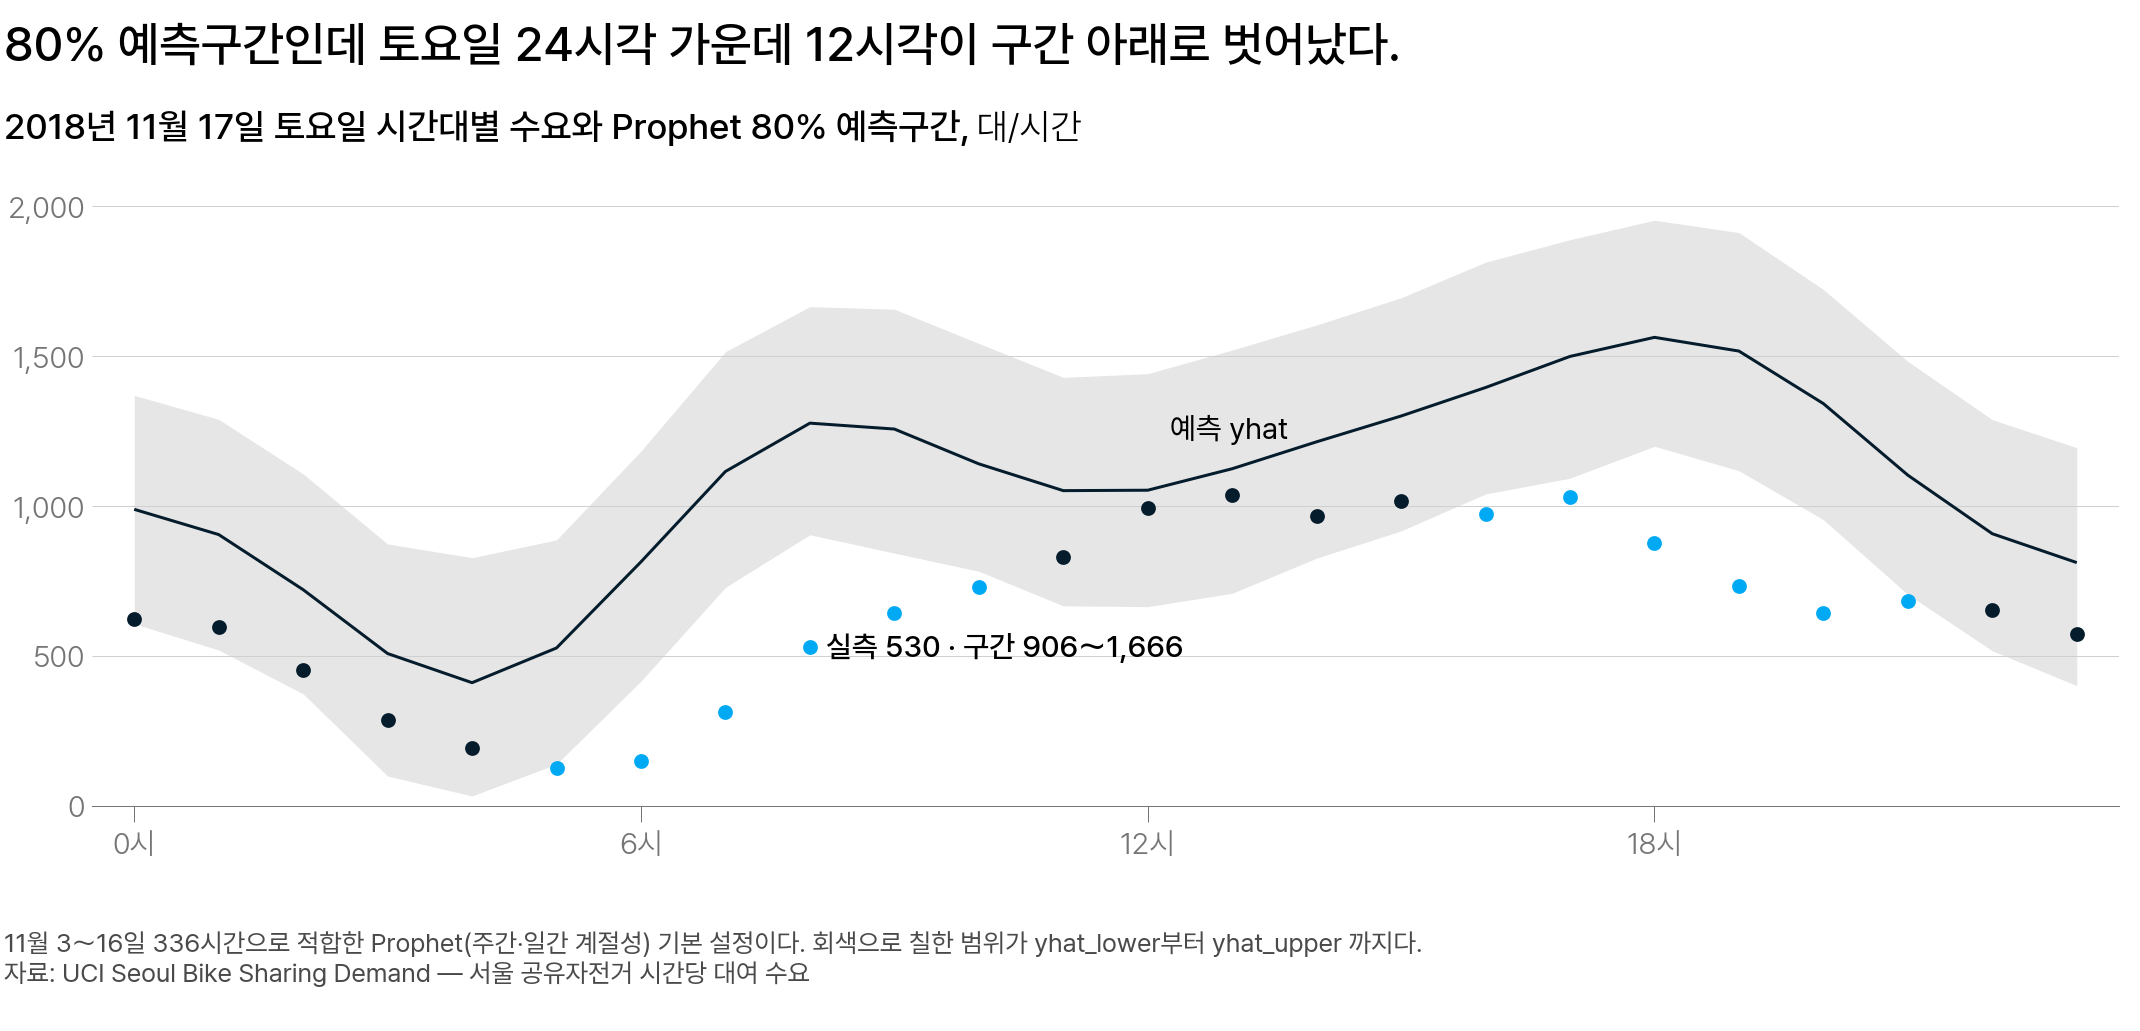

In [ ]:
# 도해 생성 코드는 LMS 에서만 실행됩니다

<p align="center"><em>▲ 11월 17일 토요일의 Prophet 예측(남색 선)과 80% 예측구간(회색으로 칠한 범위), 실측(점). 구간 아래로 벗어난 12시각은 하늘색, 구간 안에 든 12시각은 남색이다</em></p>

24시각 전체로는 벗어난 12시각(5～10시, 16～21시)이 출근·퇴근 시각에 몰려 있고, 포함률은 12 ÷ 24 = 50% 입니다. 그래서 이날의 80% 구간은 그대로 배차 판단에 쓸 수 없고, 구간을 넓히기 전에 예측선의 치우침부터 봅니다.

## 왜 명목 포함률과 실제 포함률이 어긋나는가

80% 구간이면 19시각쯤 들어올 것 같은데 왜 12시각뿐일까요? 오차항만 있다면 실측은 예측선 위아래로 번갈아 나옵니다. 그런데 11월 17일은 모형이 평일 모양과 높은 추세를 그려 24시각 모두 실측이 예측선보다 낮았습니다. 구간은 예측선을 가운데 두고 만들므로, 예측선이 치우친 날에는 포함률이 명목 포함률보다 크게 낮아집니다.

## 구간 길이는 어디에서 오는가

8시 구간의 길이는 1,666 − 906 = 760대/시간이고, 토요일 24시각 평균은 775대/시간입니다. 구간 길이에는 미래 추세의 불확실성과 오차항이 들어가고, 계수의 불확실성은 들어가지 않습니다.

| 원인 | 어디에서 오나 | 기본 구간에 들어오나 |
|---|---|---|
| 미래 추세의 불확실성 | 과거에 꺾인 만큼 미래에도 꺾이는 표본 경로를 만듭니다 | 들어옵니다. 24시간 뒤까지의 예측에서는 작습니다 |
| 오차항 $\varepsilon_t$ | 성분으로 설명되지 않고 남는 값입니다 | 들어옵니다. 길이의 거의 전부입니다 |
| 계수의 불확실성 | 계절 계수 $a_n$·$b_n$ 과 휴일 계수 $\kappa_i$ 도 표본마다 달라집니다 | 들어오지 않습니다. 기본 적합이 계수를 값 하나로 고정해 씁니다 |

학습 336시간 잔차로 계산한 오차항만의 80% 구간 길이는 약 776 으로, 토요일 평균 775 와 거의 같습니다. 그래서 기본 구간의 길이는 학습 잔차의 크기가 정합니다.

포함률이 명목 포함률보다 낮으면 실측이 벗어난 방향부터 봅니다.

| 선택지 | 특징 | 이런 경우에 쓴다 | 서울 공유자전거에서 |
|---|---|---|---|
| 예측선 고치기 | 구성을 바꿔 치우침을 없앰 | 한쪽으로만 벗어날 때 | 11월 17일(24시각 모두 예측선 아래). 조건부 계절성으로 검증 RMSE 310.34 → 274.78 |
| 명목 포함률 높이기 | 구간이 길어지고 치우침은 남음 | 위아래로 고르게 벗어날 때 | 17일은 해당하지 않음 |
| 계수 불확실성 더하기([`mcmc_samples`](https://facebook.github.io/prophet/docs/uncertainty_intervals.html)) | 계절·휴일 계수의 흔들림을 더함. 적합이 몇 초에서 몇 분으로 길어짐 | 관측이 적은 계수의 비중이 클 때 | 쓰지 않음. 17일은 한쪽 치우침이고 휴일 계수는 보고하지 않음 |

## 보고할 때 적는 이름 — 예측구간과 명목 포함률

**신뢰구간(confidence interval)** 은 그 시각의 참 평균 수요(기댓값)가 들어 있을 범위입니다. 예측구간은 실제로 관측될 값 하나가 들어올 범위라 오차항만큼 더 깁니다.

셋째 날 「신뢰수준 95%」라 부른 구간도 관측 하나가 들어올 범위라, 이름은 95% 예측구간이고 95% 는 명목 포함률입니다.

그래서 보고서에는 신뢰구간이 아니라 예측구간이라 적고, 열 이름에도 `lo80`·`hi80` 처럼 명목 포함률을 적습니다.

<details class="lms-extra"><summary>더 깊이 — 범례의 confidence interval, 80%·95% 를 함께 그린 예측</summary>

<img src="https://assets.mbrenndoerfer.com/_optimized/notebooks/prophet_files/prophet-complete-forecast-ecommerce-sales-1920w.webp" width="640" height="431"/>
<p align="center"><em>▲ Prophet 의 기본 예측 그림. 검은 점이 실측, 파란 선이 yhat, 옅은 파란 영역이 yhat_lower 부터 yhat_upper 까지다 (출처: Marcel Brenndoerfer, "Prophet: Time Series Forecasting")</em></p>

그림의 범례에는 confidence interval 이라 적혀 있지만, 이 구간이 답하는 질문은 「다음 달 매출이 어느 범위에 들어올까」라 예측구간입니다.

전력 수요 예측 하나에 80% 와 95% 를 함께 그리면 구간 길이가 이만큼 달라집니다.

<img src="https://otexts.com/fpp3/fpp_files/figure-html/prophetfc-1.png" width="640" height="395"/>
<p align="center"><em>▲ 반시간 단위 전력 수요의 2일 예측. 검은 선이 실측이고 그 뒤로 파란 예측이 이어지는데, 진한 80% 구간보다 연한 95% 구간이 위아래로 더 멀리 떨어져 구간 길이는 명목 포함률에 따라 달라진다 (출처: Hyndman & Athanasopoulos, FPP3 Figure 12.12)</em></p>

</details>

<div class="lms-summary">

**정리**

보고서에는 「80% 예측구간」처럼 이름에 명목 포함률을 적고, 검증 구간의 실제 포함률도 함께 적습니다. 11월 17일은 80% 구간이 실측을 50% 만 담았고 벗어난 시각은 모두 하한 아래였습니다. 그래서 구간을 넓히지 않고 예측선부터 고칩니다.

- 명목 포함률은 코드에 적어 두지 않고 `m.interval_width` 에서 읽습니다(기본 0.80). 다른 모형의 구간과 견줄 때는 `interval_width=0.95` 처럼 같은 값으로 맞춥니다
- 실제 포함률이 명목 포함률보다 낮을 때 한쪽으로만 벗어났으면 예측선을 고치고, 위아래로 고르게 벗어났으면 명목 포함률을 높입니다
- 기본 구간에는 계절·휴일 계수의 불확실성이 빠져 있다고 적고, 더해야 하면 `mcmc_samples` 를 씁니다

기본 예측구간은 추세와 오차항만 담은 80% 구간이라 명목 포함률과 담은 성분을 함께 보고합니다.

</div>

> **[문제] 명목 포함률이 다른 두 예측구간의 비교**
>
> 셋째 날 SARIMA 예측표는 열 이름이 `lo95`·`hi95` 이고, 오늘 Prophet 예측은 기본 설정 그대로 뽑았습니다. 두 예측을 겹쳐 그렸더니 Prophet 쪽 구간이 눈에 띄게 짧았습니다. 팀장이 "Prophet 이 더 정확한 모형이네요" 라고 말합니다. 이 결론이 왜 성급한지 두 가지 이유를 적고, 두 모형을 공정하게 비교하려면 무엇을 먼저 맞춰야 하는지 한 문장으로 쓰세요.

## 9. 예측 원점 5개 비교와 Prophet 구성 순서

Prophet 을 운영 예측에 써도 될까요? 쓴다면 어떤 구성이어야 할까요?

넷째 날처럼 예측 원점 5개의 RMSE 를 대표 지표로, MASE 를 보조 지표로 씁니다. 테스트 구간(11월 24～30일)은 쓰지 않았습니다.

## RMSE: 큰 빗나감을 더 무겁게 친 평균 오차(대/시간)

넷째 날 본 **평균 제곱근 오차(root mean squared error, RMSE)** 는 오차를 제곱해 평균한 뒤 제곱근을 씌운 값입니다.

$$
\text{RMSE} = \sqrt{\frac{1}{n}\sum_{t=1}^{n} e_t^{\,2}}
$$

$e_t$ 는 실측에서 예측을 뺀 오차, $n$ 은 채점한 시각 수(예측 원점 하나에 168)입니다.

베이스라인의 예측 원점 5개 평균 RMSE 는 363.55 입니다. 크게 빗나간 시각에 무게를 더 두어 평균하면 한 시각에 약 364대씩 빗나갔다는 뜻입니다.

- **좋은 점**: 한 시각에 몰린 큰 빗나감이 점수에 드러납니다. 오차 10, 10, 10, 10 과 0, 0, 0, 40 은 오차 절댓값의 평균(MAE)이 둘 다 10 이지만 RMSE 는 10 과 20 입니다.
- **약한 점**: 드문 날의 큰 빗나감 몇 개가 점수를 거의 정합니다. 11월 2일 예측 원점의 베이스라인은 168시간 제곱 오차의 74% 가 비가 46mm 내린 11월 8일 하루에서 나왔습니다.

## MASE: 학습 구간의 나이브 규칙보다 몇 배 빗나갔나

넷째 날 본 **평균 절대 스케일 오차(mean absolute scaled error, MASE)** 는 배율로 적는 오차 지표입니다. 검증 구간의 MAE 를 학습 구간 나이브 규칙의 MAE 로 나눕니다.

$$
\text{MASE} = \frac{\text{검증 구간의 MAE}}{Q}
$$

$Q$ 는 학습 구간에서 하루 전 같은 시각 값을 쓴 규칙(계절 나이브 24)의 MAE 로, 295.40대입니다.

MASE 가 1 보다 작으면 이 하루 전 규칙이 학습 구간에서 낸 오차보다 덜 빗나갔다는 뜻입니다. 베이스라인의 MASE 0.75 는 예측 원점 5개 평균 MAE 220.08대가 $Q$ 의 0.75배였다는 뜻입니다.

- **좋은 점**: 단위가 없는 배율이라 규모가 다른 계열끼리 비교할 수 있습니다(MAE 4대·$Q$ 8대와 MAE 400대·$Q$ 800대는 둘 다 0.5).
- **약한 점**: 1 보다 작아도 같은 예측 원점에서 베이스라인을 이겼다는 뜻은 아닙니다. Prophet 기본 구성의 0.97 은 1 보다 작지만 베이스라인의 0.75 보다 더 빗나간 값입니다.
- **이럴 때 쓴다**: 계열이 하나인 서울에서는 $Q$ 가 고정되어 MASE 순위가 MAE 순위와 같습니다. 그래서 RMSE 순위가 큰 빗나감 몇 개에 끌려간 것인지 확인하는 보조 지표로 씁니다.

In [ ]:
# 계절 나이브 168 로 예측 원점 5개를 다시 채점하고, 휴무 시각과 11월 2일 원점의 오차가 몰린 날을 본다
import numpy as np
import pandas as pd

try:
    raw = load_csv("datasets/SeoulBikeData.csv")            # LMS 에서는 LMS 가 올려 둔 자료를 이 함수로 읽는다
except NameError:                                           # Colab·내 컴퓨터에는 이 함수가 없어 UCI 원본 주소에서 받는다
    SRC = ("https://archive.ics.uci.edu/static/public/560/"
           "seoul+bike+sharing+demand.zip")
    raw = pd.read_csv(SRC, encoding="cp1252", compression="zip")
raw.columns = ["date", "count", "hour", "temp", "humidity", "wind", "visibility",
               "dewpoint", "solar", "rain", "snow", "season", "holiday", "functioning"]
raw.index = pd.to_datetime(raw["date"], format="%d/%m/%Y") + pd.to_timedelta(raw["hour"], unit="h")
raw = raw.sort_index()
off = raw["functioning"].eq("No")
s = raw["count"].astype(float).mask(raw["functioning"].eq("No"))   # 휴무 시각은 비워 두고
y = s.fillna(s.shift(168))                                          # 1주일 전 같은 시각 값으로 채우고
y = y.fillna(y.shift(-168))                                         # 앞 주가 없으면 1주일 뒤 값으로 채운다

train = y["2018-09-01 00:00":"2018-11-16 23:00"]
Q = (train - train.shift(24)).abs().mean()                   # 하루 전 같은 시각을 예측으로 쓴 규칙의 MAE
rows = []
for o in ["2018-10-19", "2018-10-26", "2018-11-02", "2018-11-09", "2018-11-16"]:
    idx = pd.date_range(f"{o} 23:00", periods=169, freq="h")[1:]      # 예측 원점 다음 168시간
    err = y[idx].to_numpy() - y[idx - pd.Timedelta(hours=168)].to_numpy()
    rows.append((pd.Timestamp(o), np.sqrt((err ** 2).mean()), np.abs(err).mean()))
rm, ma = np.mean([r[1] for r in rows]), np.mean([r[2] for r in rows])

idx = pd.date_range("2018-11-03 00:00", periods=168, freq="h")    # 11월 2일 23시 예측 원점 다음 168시간
err = y[idx].to_numpy() - y[idx - pd.Timedelta(hours=168)].to_numpy()
table = pd.DataFrame({"sq": err ** 2, "rain": raw.loc[idx, "rain"].to_numpy(),
                      "demand": y[idx].to_numpy()}, index=idx).groupby(idx.date).sum()
table["share"] = table["sq"] / table["sq"].sum()                   # 168시간 제곱 오차 가운데 그날의 비율
top = table["share"].idxmax()

print(f"베이스라인(1주일 전 같은 시각 값) 예측 원점 5개 평균 RMSE {rm:.2f} · 평균 MAE {ma:.2f}"
      f" → MASE {ma / Q:.2f} (분모 {Q:.2f}대)")
for o, r_, m_ in rows:
    print(f"  예측 원점 {o.month}월 {o.day}일 23시  RMSE {r_:7.2f}  MASE {m_ / Q:.2f}")
print(f"11월 2일 예측 원점: 168시간 제곱 오차의 {table.loc[top, 'share']:.0%} 가"
      f" 비가 {table.loc[top, 'rain']:.0f}mm 내린 {top.month}월 {top.day}일 하루에서 나왔다")
print(f"휴무 {off.sum()}시간(대여 {raw.loc[off, 'count'].sum()}대)은 1주일 전 같은 시각 값으로 채웠다")
assert round(Q, 2) == 295.40 and round(rm, 2) == 363.55 and round(ma, 2) == 220.08
assert off.sum() == 295 and round(table["share"].iloc[5], 2) == 0.74 and round(table["rain"].iloc[5]) == 46 and table.index[5] == top

## Prophet 은 베이스라인보다 나은가

| 예측 원점(금요일 23시)별 RMSE | 베이스라인(계절 나이브 168) | 셋째 날 SARIMA | Prophet 기본 구성(휴일 효과 넣음) | Prophet 조건부 계절성 |
|---|---|---|---|---|
| 10월 19일 | 306.52 | 345.39 | 366.10 | 334.69 |
| 10월 26일 | 418.18 | 368.10 | 410.81 | 376.88 |
| 11월 2일 | 457.07 | 508.05 | 475.53 | 454.77 |
| 11월 9일 | 430.72 | 317.67 | 344.54 | 319.38 |
| 11월 16일 | 205.25 | 386.08 | 310.34 | 274.78 |
| 평균 RMSE(대/시간) | 363.55 | 385.06 | 381.47 | 352.10 |
| 평균 MASE(배율, 단위 없음) | 0.75 | 0.91 | 0.97 | 0.90 |

원점마다 가장 낮은 방법이 바뀝니다. 10월 19일과 11월 16일은 베이스라인이, 11월 9일은 셋째 날 SARIMA 가 가장 낮았습니다. 그래서 한 주의 순위로 고르지 않고 원점 5개 평균으로 고릅니다.

표 밖 구성도 원점 5개로 채점했습니다. 평균 RMSE 는 일간 계절성 차수 10 이 358.41, 곱셈 계절성이 359.32, 강수만 더한 구성이 378.76 입니다. MASE 는 셋 모두 0.89～0.93 으로 베이스라인 0.75 보다 높습니다.

| 질문 | 비교하는 두 구성의 평균 RMSE(대/시간) | 답 |
|---|---|---|
| Prophet 기본 구성은 베이스라인보다 나은가 | Prophet 기본 구성 381.47, 베이스라인 363.55 | 아니요. 17.92 높아 투입하지 않음 |
| 셋째 날 SARIMA 보다 나은가 | Prophet 기본 구성 381.47, SARIMA 385.06 | 지표에 따라 엇갈림. RMSE 는 3.59 낮지만 MASE 는 0.97 로 SARIMA 0.91 보다 높음 |
| 날씨를 더하면 나아지는가 | 날씨 포함 396.45, Prophet 기본 구성 381.47 | 아니요. 실측 날씨를 대입한 사후 예측에서도 14.98 커지고, 강수만 더해도 베이스라인보다 높음 |
| 조건부 계절성은 베이스라인보다 나은가 | 조건부 계절성 352.10, 베이스라인 363.55 | 지표에 따라 엇갈림. RMSE 는 11.45 낮지만 MASE 는 0.90 으로 베이스라인 0.75 보다 높음 |

두 지표가 엇갈리면 어느 빗나감이 더 비싼지로 고릅니다. 자전거가 크게 모자라는 시각이 비싼 이 자료에서는 큰 빗나감을 무겁게 치는 RMSE 를 따릅니다.

- 운영팀 질문 2: RMSE 로 보면 Prophet 기본 구성이 셋째 날 SARIMA 보다 3.59 낮아 조금 낫습니다
- 투입: Prophet 기본 구성은 두 지표 모두 베이스라인보다 높아 투입하지 않습니다
- 후보: RMSE 가 베이스라인보다 낮은 세 구성입니다. 조건부 계절성은 11.45, 차수 10 은 5.14, 곱셈 계절성은 4.23 낮습니다

다만 세 후보 모두 MASE 는 베이스라인보다 높습니다. MASE 는 MAE 를 $Q$ 로 나눈 값입니다. 그래서 오차 절댓값의 평균으로는 더 빗나갔고, 큰 빗나감만 줄였다는 뜻입니다. 큰 빗나감은 드문 날 몇 개가 정하므로, 이 우위가 다른 주에도 이어지는지는 아직 알 수 없습니다.

조건부 계절성과 차수 10 은 11월 16일 예측 원점의 채점 168시간(11월 17～23일)을 보고 고른 구성입니다. 채점할 기간을 보고 구성을 고르면 그 기간에 맞춘 구성이 뽑혀 점수가 실제보다 좋아 보입니다. 이것을 **선택 편향(selection bias)** 이라 합니다. 그래서 세 후보의 최종 판단은 테스트 구간에서 한 번 내립니다.

## Prophet 구성을 정하는 순서

| 이런 자료·상황이면 | 이렇게 합니다 | 서울 공유자전거에서 |
|---|---|---|
| 휴무로 0 이 된 시각이 있다 | Prophet 만 쓰면 비우고, 베이스라인과 비교하면 채웁니다 | 295시간을 채움 |
| 이력이 2년보다 짧다 | 연간 계절성을 제외합니다 | 365일이면 기본 설정이 주간 계절성만 포함함 |
| 평균 대여량이 늘면 하루 최대·최소 차이도 비례해 커진다 | `seasonality_mode='multiplicative'` 를 가법과 학습 밖 오차로 견줍니다 | 1월→6월 평균 약 6.2배·차이 약 6.4배, 원점 5개 평균 381.47 → 359.32, 후보 |
| 평일과 주말의 하루 모양이 다르다 | 일간 계절성을 평일과 주말로 나눈 조건부 계절성을 견줍니다 | 원점 5개 평균 352.10 < 베이스라인 363.55, 후보 |
| 하루 주기가 학습에 수십 번 들어 있다 | 일간 계절성의 푸리에 차수를 4～12 에서 학습 밖 오차로 견줍니다 | 원점 5개 평균 $N = 4$ 381.47 → $N = 10$ 358.41, 후보 |
| 미래값을 따로 구해야 하는 열이다 | 그 값을 어디서 가져올지 먼저 적습니다 | 실측 날씨를 대입해도 나빠져 더하지 않음 |
| `changepoint_prior_scale` 을 고른다 | 0.01·0.05·0.5 를 두고 학습 뒤 두 기간 이상의 오차로 고릅니다. 이력이 여러 해면 예측 원점을 늘립니다 | 학습 뒤 두 기간에서 가장 작은 값이 0.01 과 0.05 로 달라 기본값 0.05 를 둠 |
| 오차를 해석한다 | 베이스라인과 같은 원점에서 비교하고, 모든 방법이 함께 틀린 원점은 자료부터 봅니다 | 11월 2일 원점 168시간 제곱 오차의 46～74% 가 비 46mm 인 11월 8일 하루에서 나옴(베이스라인·SARIMA·Prophet 기본·날씨 포함 모두) |
| 예측구간을 보고한다 | 명목 포함률을 이름에 적고 실제 포함률과 벗어난 방향을 봅니다 | 11월 17일 50%(명목 80%), 12시각 모두 아래로 벗어남 |

## 성분마다 하나씩 있는 설정값

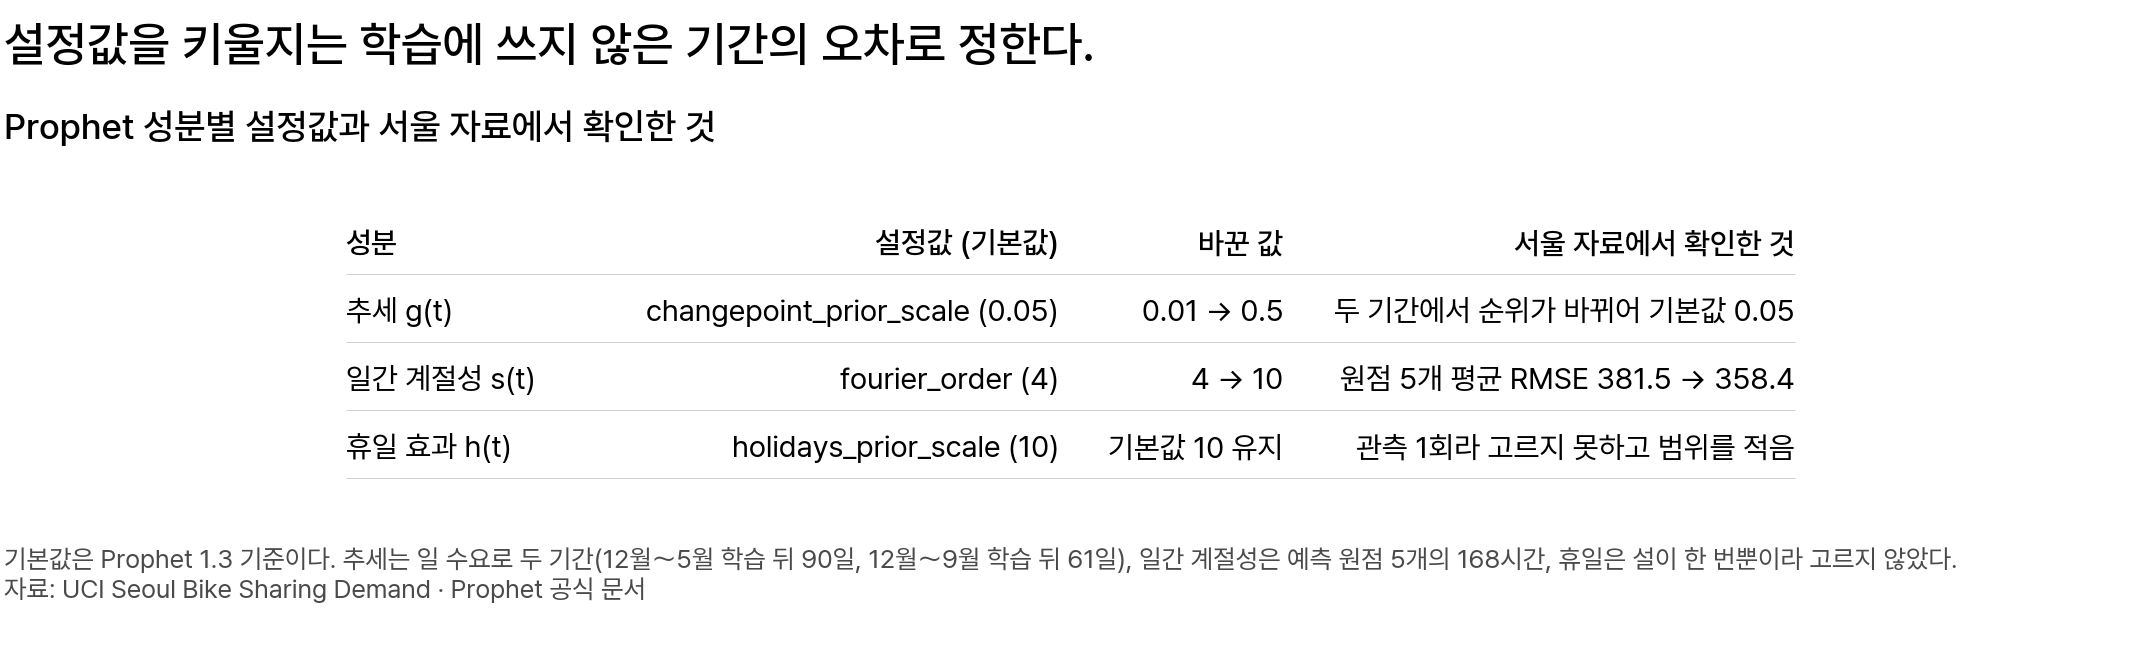

In [ ]:
# 도해 생성 코드는 LMS 에서만 실행됩니다

<p align="center"><em>▲ 성분마다 설정값 하나와 기본값, 서울 공유자전거에서 확인한 것. 추세와 일간 계절성은 학습에 쓰지 않은 기간의 RMSE 로 골랐고, 휴일은 설이 한 번뿐이라 기본값을 두었다</em></p>

<div class="lms-summary">

**정리**

Prophet 은 아직 투입하지 않고 운영 예측은 베이스라인(계절 나이브 168)으로 둡니다. Prophet 기본 구성의 예측 원점 5개 평균 RMSE 는 381.47 로 베이스라인 363.55 보다 17.92 높았습니다.

- 다음 후보는 조건부 계절성(352.10)·일간 계절성 차수 10(358.41)·곱셈 계절성(359.32)입니다. MASE 는 셋 모두 베이스라인보다 높습니다. RMSE 우위가 큰 빗나감 몇 개를 줄인 데서 나왔으므로 테스트 구간(11월 24～30일)에서 한 번 채점한 뒤 정합니다
- 날씨 열은 더하지 않습니다. 실측 날씨를 대입한 사후 예측에서도 기본 구성보다 14.98 컸고, 강수만 더해도 378.76 으로 베이스라인보다 높았습니다
- 새 구성은 같은 예측 원점 5개에서 RMSE 로 순위를 정하고 MASE 를 곁에 적습니다

성분마다 있는 설정값은 정확도가 아니라 과거를 얼마나 따라갈지를 정하므로, 학습에 쓰지 않은 기간의 오차로 고릅니다.

</div>

## 수업에서 다룰 질문

이어지는 팀 라운드는 수업에서 각자 고른 답의 분포를 먼저 공개하고, 팀으로 토론한 뒤 팀 단일 답을 냅니다.

> **[문제] 팀 라운드: 추세가 꺾이지 않았다는 결과를 어떻게 보고할 것인가**
>
> 운영팀장이 물었습니다. "1년 추세는 어디에서 꺾였습니까?" 그런데 연간 계절성을 포함한 채로 일 수요 365일에 Prophet 을 적합하면 추세는 13,095대/일에서 22,308대/일까지 **한 번도 꺾이지 않은 직선**이고 변화량이 큰 변화점은 0곳입니다. 1년의 변동은 연간 계절성이 설명합니다. 오늘 실습 미션 1 에서 같은 적합을 직접 해 이 결과를 확인합니다. 팀 안에서 다음 보고 방식을 두고 의견이 갈렸습니다.
> 
> - **관점 A: 연간 계절성을 제외하고 다시 적합해 꺾인 시점을 찾는다.** 질문은 「어디에서 꺾였나」인데, 지금 모형은 그 질문에 답할 수 없는 구성이다. 연간 계절성을 제외하면 추세가 1년의 변동을 맡아 변화량이 큰 변화점이 생기고, 그러면 시기를 지목해 보고할 수 있다.
> - **관점 B: 지금 결과를 그대로 보고한다.** 이 구성에서 추세는 1년 내내 직선으로 증가했고 계절성이 변동을 만들었다는 것이 나온 답이다. 질문의 전제가 어긋났다면 답을 만들어 내는 대신 전제를 고쳐 주는 것이 분석가의 일이다.
> - **관점 C: `changepoint_prior_scale` 을 키워 변화량이 큰 변화점이 생기는지 확인하고 그 결과까지 함께 보고한다.** `changepoint_prior_scale` 을 0.05 에서 0.5 로 증가시켜 보고, 그래도 변화량이 큰 변화점이 생기지 않으면 이 계열의 추세는 어떤 설정에서도 꺾이지 않는다는 더 강한 근거가 된다.
> 
> 자기 입장 하나와 근거 3가지, 그리고 확신도를 정해 오세요.